In [ ]:

!pip install yfinance


In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:


import pandas as pd
import requests
from io import StringIO

# Wikipedia source
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

# Identify the request as coming from a browser
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
}

# Request the Wikipedia page
response = requests.get(url, headers=headers, timeout=30)

# Check whether access was successful
response.raise_for_status()

# Extract the tables using pandas
tables = pd.read_html(StringIO(response.text))

# Select the first table
sp500 = tables[0]

# Record retrieval date
retrieval_date = pd.Timestamp.now(tz="Asia/Colombo").date()

# Select required columns
ticker_data = sp500[["Symbol", "Security", "GICS Sector"]].copy()

# Convert ticker symbols for Yahoo Finance where necessary
ticker_data["Yahoo_Ticker"] = ticker_data["Symbol"].str.replace(".", "-", regex=False)

# Display results
print("Retrieval date:", retrieval_date)
print("Total companies:", len(ticker_data))

display(ticker_data.head(10))



Retrieval date: 2026-11-21
Total companies: 503


,Symbol,Security,GICS Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN
5,ADBE,Adobe Inc.,Information Technology,ADBE
6,AMD,Advanced Micro Devices,Information Technology,AMD
7,AES,AES Corporation,Utilities,AES
8,AFL,Aflac,Financials,AFL
9,A,Agilent Technologies,Health Care,A


In [ ]:
ticker_data.to_csv("sp500_ticker_list.csv", index=False)

print("S&P 500 ticker list saved successfully!")


S&P 500 ticker list saved successfully!


In [ ]:
import yfinance as yf
import pandas as pd
import os
import time
import zipfile

# Required study period
start_date = "2021-01-01"
end_date = "2025-01-01"  # Exclusive

# Create a folder to store the downloaded data
os.makedirs("SP500_Daily_Data", exist_ok=True)

# Get Yahoo Finance ticker symbols
tickers = ticker_data["Yahoo_Ticker"].dropna().unique().tolist()

# Divide companies into groups of 50
batch_size = 50

downloaded = []
failed = []
download_summary = []

print("Total tickers to download:", len(tickers))

# Download stock data in batches
for i in range(0, len(tickers), batch_size):

    batch = tickers[i:i + batch_size]

    print(f"\nDownloading batch {i//batch_size + 1}...")

    try:
        data = yf.download(
            tickers=batch,
            start=start_date,
            end=end_date,
            auto_adjust=False,
            actions=True,
            group_by="ticker",
            progress=False,
            threads=False,
            timeout=60
        )

        for ticker in batch:

            try:
                if isinstance(data.columns, pd.MultiIndex):
                    if ticker in data.columns.get_level_values(0):
                        stock = data[ticker].copy()
                    else:
                        stock = data.xs(
                            ticker, axis=1, level=1
                        ).copy()
                else:
                    stock = data.copy()

                stock = stock.dropna(how="all")

                if stock.empty:
                    failed.append(ticker)
                    continue

                # Save individual company data
                stock.index.name = "Date"
                stock.to_csv(
                    f"SP500_Daily_Data/{ticker}.csv"
                )

                downloaded.append(ticker)

                download_summary.append({
                    "Ticker": ticker,
                    "Observations": len(stock),
                    "First_Date": stock.index.min(),
                    "Last_Date": stock.index.max()
                })

            except Exception as e:
                failed.append(ticker)
                print(f"Problem with {ticker}: {e}")

    except Exception as e:
        print("Batch download failed:", e)
        failed.extend(batch)

    time.sleep(1)

# Download the S&P 500 benchmark separately
print("\nDownloading S&P 500 benchmark...")

benchmark = yf.download(
    "^GSPC",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    actions=True,
    progress=False
)

if not benchmark.empty:
    if isinstance(benchmark.columns, pd.MultiIndex):
        benchmark.columns = benchmark.columns.get_level_values(0)

    benchmark.index.name = "Date"
    benchmark.to_csv("SP500_Daily_Data/GSPC_Benchmark.csv")

    print("Benchmark downloaded successfully!")
else:
    print("Benchmark download failed. We will investigate.")

# Create a summary of downloaded companies
download_report = pd.DataFrame(download_summary)

download_report.to_csv(
    "SP500_Daily_Data/Download_Summary.csv",
    index=False
)

print("\nDOWNLOAD RESULTS")
print("---------------------------")
print("Successful downloads:", len(downloaded))
print("Failed downloads:", len(failed))
print("Benchmark observations:", len(benchmark))

# Save failed tickers for investigation
pd.DataFrame({"Failed_Ticker": failed}).to_csv(
    "SP500_Daily_Data/Failed_Tickers.csv",
    index=False
)

display(download_report.head(10))


Total tickers to download: 503






ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')




Benchmark downloaded successfully!

DOWNLOAD RESULTS
---------------------------
Successful downloads: 498
Failed downloads: 5
Benchmark observations: 1005


,Ticker,Observations,First_Date,Last_Date
0,MMM,1005,2021-01-04,2024-12-31
1,AOS,1005,2021-01-04,2024-12-31
2,ABT,1005,2021-01-04,2024-12-31
3,ABBV,1005,2021-01-04,2024-12-31
4,ACN,1005,2021-01-04,2024-12-31
5,ADBE,1005,2021-01-04,2024-12-31
6,AMD,1005,2021-01-04,2024-12-31
7,AES,1005,2021-01-04,2024-12-31
8,AFL,1005,2021-01-04,2024-12-31
9,A,1005,2021-01-04,2024-12-31


In [ ]:
# Display the five failed ticker symbols

failed_tickers = pd.read_csv(
    "SP500_Daily_Data/Failed_Tickers.csv"
)

print("Failed ticker symbols:")
display(failed_tickers)


Failed ticker symbols:


,Failed_Ticker
0,FDXF
1,HONA
2,Q
3,SNDK
4,VYLR


In [ ]:

# Investigate the five failed ticker downloads

failed_list = failed_tickers["Failed_Ticker"].tolist()

for ticker in failed_list:

    print("\n" + "="*45)
    print("TICKER:", ticker)

    # Find original company information
    company_info = ticker_data[
        ticker_data["Yahoo_Ticker"] == ticker
    ]

    if not company_info.empty:
        display(company_info[["Symbol", "Security", "GICS Sector"]])
    else:
        print("Ticker not found in original company list.")

    # Try downloading this ticker individually
    try:
        test_data = yf.download(
            ticker,
            start="2021-01-01",
            end="2025-01-01",
            auto_adjust=False,
            progress=False,
            threads=False
        )

        if not test_data.empty:
            print("Individual download: SUCCESS")
            print("Observations:", len(test_data))
        else:
            print("Individual download: NO DATA")

    except Exception as e:
        print("Individual download: FAILED")
        print("Error:", e)



TICKER: FDXF


,Symbol,Security,GICS Sector
192,FDXF,FedEx Freight,Industrials


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Individual download: NO DATA

TICKER: HONA


,Symbol,Security,GICS Sector
233,HONA,Honeywell Aerospace,Industrials


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


... (6 outputs left out)

Individual download: NO DATA

TICKER: VYLR


,Symbol,Security,GICS Sector
478,VYLR,Vylor,Consumer Staples


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Individual download: NO DATA


In [ ]:
# Document companies excluded from the historical analysis

exclusion_log = pd.DataFrame({
    "Ticker": ["FDXF", "HONA", "Q", "SNDK", "VYLR"],
    "Company": [
        "FedEx Freight",
        "Honeywell Aerospace",
        "Qnity Electronics",
        "Sandisk",
        "Vylor"
    ],
    "Reason": [
        "Began public trading after the study period",
        "Began public trading after the study period",
        "Began public trading after the study period",
        "Began public trading after the study period",
        "Began public trading after the study period"
    ],
    "Decision": [
        "Excluded",
        "Excluded",
        "Excluded",
        "Excluded",
        "Excluded"
    ]
})

display(exclusion_log)

# Save the exclusion evidence
exclusion_log.to_csv(
    "SP500_Daily_Data/Exclusion_Log.csv",
    index=False
)

print("Exclusion log saved successfully!")


,Ticker,Company,Reason,Decision
0,FDXF,FedEx Freight,Began public trading after the study period,Excluded
1,HONA,Honeywell Aerospace,Began public trading after the study period,Excluded
2,Q,Qnity Electronics,Began public trading after the study period,Excluded
3,SNDK,Sandisk,Began public trading after the study period,Excluded
4,VYLR,Vylor,Began public trading after the study period,Excluded


Exclusion log saved successfully!


In [ ]:
# Inspect Apple's downloaded data as an example

apple = pd.read_csv(
    "SP500_Daily_Data/AAPL.csv"
)

print("Apple dataset:")
display(apple.head())

print("\nAvailable columns:")
print(apple.columns.tolist())

print("\nDataset dimensions:")
print(apple.shape)


Apple dataset:


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
0,2021-01-04,133.520004,133.610001,126.760002,129.410004,125.537102,143301900,0.0,0.0
1,2021-01-05,128.889999,131.740005,128.429993,131.009995,127.089233,97664900,0.0,0.0
2,2021-01-06,127.720001,131.050003,126.379997,126.599998,122.811188,155088000,0.0,0.0
3,2021-01-07,128.360001,131.630005,127.860001,130.919998,127.001930,109578200,0.0,0.0
4,2021-01-08,132.429993,132.630005,130.229996,132.050003,128.098083,105158200,0.0,0.0



Available columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Dividends', 'Stock Splits']

Dataset dimensions:
(1005, 9)


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

backup_path = "/content/drive/MyDrive/SP500_Daily_Data.zip"

if os.path.exists(backup_path):
    print("Backup found successfully!")
    print("File size:",
          round(os.path.getsize(backup_path)/(1024*1024), 2),
          "MB")
else:
    print("Backup ZIP not found. We need to locate it in Google Drive.")


Backup ZIP not found. We need to locate it in Google Drive.


In [ ]:

from google.colab import drive
import os

# Make sure Google Drive is connected
drive.mount('/content/drive')

# Display files in the main Google Drive folder
drive_path = "/content/drive/MyDrive"

print("Files in My Drive:")

for item in os.listdir(drive_path):
    print(item)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files in My Drive:
Colab Notebooks
Student Details SRS.pdf
L5 Web Enabled Business.pdf
week1_computerSeminar.ipynb
Arrays_and_Dataframe.ipynb
Maneth Sesara Premarathne Internship CV (1).pdf
Maneth Sesara Premarathne Internship CV.pdf
Project Idea File.pdf


In [ ]:

import os

drive_path = "/content/drive/MyDrive"

found_files = []

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file == "SP500_Daily_Data.zip":
            found_files.append(os.path.join(root, file))

if found_files:
    print("Backup found!")
    for path in found_files:
        print(path)
else:
    print("Backup ZIP not found anywhere in My Drive.")


Backup ZIP not found anywhere in My Drive.


In [ ]:

from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Create a permanent coursework folder
main_folder = "/content/drive/MyDrive/6BUIS017W_CWK1"

data_folder = os.path.join(
    main_folder,
    "SP500_Daily_Data"
)

os.makedirs(data_folder, exist_ok=True)

print("Google Drive connected successfully!")
print("Coursework folder:", main_folder)
print("Data folder:", data_folder)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!
Coursework folder: /content/drive/MyDrive/6BUIS017W_CWK1
Data folder: /content/drive/MyDrive/6BUIS017W_CWK1/SP500_Daily_Data


In [ ]:

import pandas as pd
import requests
from io import StringIO

# Wikipedia source
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

headers = {
    "User-Agent": "Mozilla/5.0"
}

# Retrieve the webpage
response = requests.get(
    url,
    headers=headers,
    timeout=30
)

response.raise_for_status()

# Extract the S&P 500 table
tables = pd.read_html(StringIO(response.text))

sp500 = tables[0]

# Record retrieval date
retrieval_date = pd.Timestamp.now(
    tz="Asia/Colombo"
).date()

# Prepare ticker information
ticker_data = sp500[
    ["Symbol", "Security", "GICS Sector"]
].copy()

# Convert ticker symbols for Yahoo Finance
ticker_data["Yahoo_Ticker"] = (
    ticker_data["Symbol"].str.replace(".", "-", regex=False)
)

# Save directly to Google Drive
ticker_data.to_csv(
    os.path.join(data_folder, "SP500_Ticker_List.csv"),
    index=False
)

print("Retrieval date:", retrieval_date)
print("Total ticker entries:", len(ticker_data))

display(ticker_data.head(10))

print("\nTicker list saved to Google Drive!")


Retrieval date: 2026-11-21
Total ticker entries: 503


,Symbol,Security,GICS Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN
5,ADBE,Adobe Inc.,Information Technology,ADBE
6,AMD,Advanced Micro Devices,Information Technology,AMD
7,AES,AES Corporation,Utilities,AES
8,AFL,Aflac,Financials,AFL
9,A,Agilent Technologies,Health Care,A



Ticker list saved to Google Drive!


In [ ]:

# Save acquisition information

retrieval_info = pd.DataFrame({
    "Item": [
        "Data Source",
        "Ticker List Source",
        "Retrieval Date",
        "Study Start Date",
        "Study End Date",
        "Download Method"
    ],
    "Details": [
        "Yahoo Finance",
        "Wikipedia - S&P 500 constituents",
        str(retrieval_date),
        "2021-01-01",
        "2025-01-01 (exclusive)",
        "Python yfinance"
    ]
})

retrieval_info.to_csv(
    os.path.join(main_folder, "Acquisition_Information.csv"),
    index=False
)

display(retrieval_info)


,Item,Details
0,Data Source,Yahoo Finance
1,Ticker List Source,Wikipedia - S&P 500 constituents
2,Retrieval Date,2026-11-21
3,Study Start Date,2021-01-01
4,Study End Date,2025-01-01 (exclusive)
5,Download Method,Python yfinance


In [ ]:

import yfinance as yf
import pandas as pd
import numpy as np
import os
import time

# Study period
start_date = "2021-01-01"
end_date = "2025-01-01"

# Obtain ticker symbols
tickers = ticker_data["Yahoo_Ticker"].dropna().unique().tolist()

# Track results
successful = []
failed = []

batch_size = 25

print("Total unique ticker symbols:", len(tickers))

# Download in batches
for i in range(0, len(tickers), batch_size):

    batch = tickers[i:i + batch_size]

    print(
        f"\nProcessing batch {i//batch_size + 1} "
        f"of {int(np.ceil(len(tickers)/batch_size))}"
    )

    try:
        batch_data = yf.download(
            tickers=batch,
            start=start_date,
            end=end_date,
            auto_adjust=False,
            actions=True,
            group_by="ticker",
            progress=False,
            threads=False,
            timeout=60
        )

        for ticker in batch:

            save_path = os.path.join(
                data_folder, f"{ticker}.csv"
            )

            # Skip previously saved, non-empty files
            if os.path.exists(save_path) and os.path.getsize(save_path) > 100:
                successful.append(ticker)
                continue

            try:
                if isinstance(batch_data.columns, pd.MultiIndex):

                    if ticker in batch_data.columns.get_level_values(0):
                        stock = batch_data[ticker].copy()

                    elif ticker in batch_data.columns.get_level_values(1):
                        stock = batch_data.xs(
                            ticker, axis=1, level=1
                        ).copy()

                    else:
                        failed.append(ticker)
                        continue

                else:
                    if len(batch) == 1:
                        stock = batch_data.copy()
                    else:
                        failed.append(ticker)
                        continue

                stock = stock.dropna(how="all")

                if stock.empty:
                    failed.append(ticker)
                    continue

                stock.index.name = "Date"

                # Save directly to Google Drive
                stock.to_csv(save_path)

                successful.append(ticker)

            except Exception as e:
                print("Problem with", ticker, ":", e)
                failed.append(ticker)

    except Exception as e:
        print("Batch error:", e)
        failed.extend(batch)

    print("Successful so far:", len(set(successful)))
    print("Failed so far:", len(set(failed)))

    time.sleep(1)

# Download benchmark separately
print("\nDownloading S&P 500 benchmark...")

benchmark_path = os.path.join(
    data_folder, "GSPC_Benchmark.csv"
)

benchmark = yf.download(
    "^GSPC",
    start=start_date,
    end=end_date,
    auto_adjust=False,
    actions=True,
    progress=False
)

if not benchmark.empty:

    if isinstance(benchmark.columns, pd.MultiIndex):
        benchmark.columns = benchmark.columns.get_level_values(0)

    benchmark.index.name = "Date"
    benchmark.to_csv(benchmark_path)

    print("Benchmark saved successfully!")

else:
    print("Benchmark download failed.")

# Save download summary
download_summary = pd.DataFrame({
    "Ticker": list(dict.fromkeys(successful))
})

download_summary.to_csv(
    os.path.join(data_folder, "Download_Summary.csv"),
    index=False
)

# Save failed tickers
pd.DataFrame({
    "Failed_Ticker": list(dict.fromkeys(failed))
}).to_csv(
    os.path.join(data_folder, "Failed_Tickers.csv"),
    index=False
)

print("\nFINAL DOWNLOAD RESULTS")
print("----------------------------")
print("Successful:", len(set(successful)))
print("Failed:", len(set(failed)))
print("Benchmark observations:", len(benchmark))
print("Storage location:", data_folder)


Total unique ticker symbols: 503

Processing batch 1 of 21
Successful so far: 25
Failed so far: 0

Processing batch 2 of 21
Successful so far: 50
Failed so far: 0

Processing batch 3 of 21
Successful so far: 75
Failed so far: 0

Processing batch 4 of 21
Successful so far: 100
Failed so far: 0

Processing batch 5 of 21
Successful so far: 125
Failed so far: 0

Processing batch 6 of 21
Successful so far: 150
Failed so far: 0

Processing batch 7 of 21
Successful so far: 175
Failed so far: 0

Processing batch 8 of 21


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Successful so far: 199
Failed so far: 1

Processing batch 9 of 21
Successful so far: 224
Failed so far: 1

Processing batch 10 of 21


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Successful so far: 248
Failed so far: 2

Processing batch 11 of 21
Successful so far: 273
Failed so far: 2

Processing batch 12 of 21
Successful so far: 298
Failed so far: 2

Processing batch 13 of 21
Successful so far: 323
Failed so far: 2

Processing batch 14 of 21
Successful so far: 348
Failed so far: 2

Processing batch 15 of 21
Successful so far: 373
Failed so far: 2

Processing batch 16 of 21


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Successful so far: 397
Failed so far: 3

Processing batch 17 of 21


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Successful so far: 421
Failed so far: 4

Processing batch 18 of 21
Successful so far: 446
Failed so far: 4

Processing batch 19 of 21
Successful so far: 471
Failed so far: 4

Processing batch 20 of 21


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Successful so far: 495
Failed so far: 5

Processing batch 21 of 21
Successful so far: 498
Failed so far: 5

Benchmark saved successfully!

FINAL DOWNLOAD RESULTS
----------------------------
Successful: 498
Failed: 5
Benchmark observations: 1005
Storage location: /content/drive/MyDrive/6BUIS017W_CWK1/SP500_Daily_Data


In [ ]:

# Verify files stored in Google Drive

stock_files = [
    f for f in os.listdir(data_folder)
    if f.endswith(".csv")
    and f not in [
        "GSPC_Benchmark.csv",
        "Download_Summary.csv",
        "Failed_Tickers.csv",
        "Exclusion_Log.csv",
        "Validation_Results.csv"
    ]
]

print("Company datasets saved:", len(stock_files))

print(
    "Benchmark saved:",
    os.path.exists(
        os.path.join(data_folder, "GSPC_Benchmark.csv")
    )
)

print("Permanent storage verified!")


Company datasets saved: 499
Benchmark saved: True
Permanent storage verified!


In [ ]:

import os
import pandas as pd

# Read ticker list from the correct location
ticker_data = pd.read_csv(
    os.path.join(data_folder, "SP500_Ticker_List.csv")
)

expected_tickers = set(
    ticker_data["Yahoo_Ticker"].dropna().unique()
)

# Exclude all supporting files from company counts
metadata_files = {
    "GSPC_Benchmark.csv",
    "Download_Summary.csv",
    "Failed_Tickers.csv",
    "Exclusion_Log.csv",
    "Validation_Results.csv",
    "SP500_Ticker_List.csv"
}

downloaded_tickers = {
    f.replace(".csv", "")
    for f in os.listdir(data_folder)
    if f.endswith(".csv") and f not in metadata_files
}

missing_tickers = expected_tickers - downloaded_tickers
unexpected_tickers = downloaded_tickers - expected_tickers

print("EXPECTED UNIQUE TICKERS:", len(expected_tickers))
print("DOWNLOADED COMPANIES:", len(downloaded_tickers))
print("NOT DOWNLOADED:", len(missing_tickers))
print("UNEXPECTED FILES:", len(unexpected_tickers))

print("\nTickers not downloaded:")
print(sorted(missing_tickers))

print("\nUnexpected files:")
print(sorted(unexpected_tickers))

# Display failed download log
failed_path = os.path.join(data_folder, "Failed_Tickers.csv")

if os.path.exists(failed_path):
    print("\nFailed download log:")
    display(pd.read_csv(failed_path))


EXPECTED UNIQUE TICKERS: 503
DOWNLOADED COMPANIES: 498
NOT DOWNLOADED: 5
UNEXPECTED FILES: 0

Tickers not downloaded:
['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']

Unexpected files:
[]

Failed download log:


,Failed_Ticker
0,FDXF
1,HONA
2,Q
3,SNDK
4,VYLR


In [ ]:

# TASK 1.2 - COMPANY DATA VALIDATION

import os
import pandas as pd
import numpy as np

validation_results = []

study_start = pd.Timestamp("2021-01-01")
study_end = pd.Timestamp("2025-01-01")

required_columns = [
    "Open", "High", "Low", "Close", "Adj Close", "Volume"
]

# Identify company CSV files
metadata_files = {
    "GSPC_Benchmark.csv",
    "Download_Summary.csv",
    "Failed_Tickers.csv",
    "Exclusion_Log.csv",
    "Validation_Results.csv",
    "SP500_Ticker_List.csv"
}

stock_files = [
    f for f in os.listdir(data_folder)
    if f.endswith(".csv") and f not in metadata_files
]

print("Company files found:", len(stock_files))

# Validate each company
for file in sorted(stock_files):

    ticker = file.replace(".csv", "")

    df = pd.read_csv(
        os.path.join(data_folder, file),
        parse_dates=["Date"]
    )

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        print(ticker, "Missing columns:", missing_columns)
        continue

    # Duplicate dates
    duplicates = df["Date"].duplicated().sum()

    # Missing values in required fields
    missing_values = df[required_columns].isna().sum().sum()

    # Non-positive prices
    invalid_prices = (
        df[required_columns[:-1]].le(0).any(axis=1)
    ).sum()

    # Invalid volume
    invalid_volume = (
        df["Volume"].isna() | (df["Volume"] <= 0)
    ).sum()

    # OHLC consistency
    invalid_ohlc = (
        (df["High"] < df["Low"]) |
        (df["High"] < df["Open"]) |
        (df["High"] < df["Close"]) |
        (df["Low"] > df["Open"]) |
        (df["Low"] > df["Close"])
    ).sum()

    # Check study period
    outside_period = (
        (df["Date"] < study_start) |
        (df["Date"] >= study_end)
    ).sum()

    # Corporate actions
    dividends = (
        df["Dividends"].fillna(0).ne(0).sum()
        if "Dividends" in df.columns else np.nan
    )

    splits = (
        df["Stock Splits"].fillna(0).ne(0).sum()
        if "Stock Splits" in df.columns else np.nan
    )

    validation_results.append({
        "Ticker": ticker,
        "Observations": len(df),
        "First_Date": df["Date"].min(),
        "Last_Date": df["Date"].max(),
        "Duplicate_Dates": duplicates,
        "Missing_Values": missing_values,
        "Invalid_Prices": invalid_prices,
        "Invalid_Volume": invalid_volume,
        "Invalid_OHLC": invalid_ohlc,
        "Outside_Period": outside_period,
        "Dividend_Days": dividends,
        "Stock_Split_Days": splits
    })

# Create results table
validation_df = pd.DataFrame(validation_results)

print("\nTOTAL COMPANIES VALIDATED:", len(validation_df))

display(validation_df.head(10))

# Overall summary
print("\nOVERALL VALIDATION SUMMARY")

display(
    validation_df.select_dtypes(include="number")
    .sum()
    .to_frame("Total")
)

# Save report directly to Google Drive
validation_df.to_csv(
    os.path.join(data_folder, "Validation_Results.csv"),
    index=False
)

print("\nValidation report saved successfully!")


Company files found: 498

TOTAL COMPANIES VALIDATED: 498


,Ticker,Observations,First_Date,Last_Date,Duplicate_Dates,Missing_Values,Invalid_Prices,Invalid_Volume,Invalid_OHLC,Outside_Period,Dividend_Days,Stock_Split_Days
0,A,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,17,0
1,AAPL,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0
2,ABBV,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0
3,ABNB,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0
4,ABT,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0
5,ACGL,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,1,0
6,ACN,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0
7,ADBE,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,0,0
8,ADI,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0
9,ADM,1005,2021-01-04,2024-12-31,0,0,0,0,0,0,16,0



OVERALL VALIDATION SUMMARY


,Total
Observations,496304
Duplicate_Dates,0
Missing_Values,0
Invalid_Prices,0
Invalid_Volume,451
Invalid_OHLC,1
Outside_Period,0
Dividend_Days,6086
Stock_Split_Days,61



Validation report saved successfully!


In [ ]:

# Investigate invalid trading volumes

volume_issues = []

for file in sorted(stock_files):

    ticker = file.replace(".csv", "")

    df = pd.read_csv(
        os.path.join(data_folder, file),
        parse_dates=["Date"]
    )

    # Identify zero, negative or missing volume
    problem_rows = df[
        df["Volume"].isna() | (df["Volume"] <= 0)
    ]

    for _, row in problem_rows.iterrows():

        volume_issues.append({
            "Ticker": ticker,
            "Date": row["Date"],
            "Volume": row["Volume"]
        })

volume_issues_df = pd.DataFrame(volume_issues)

print("Total invalid-volume observations:",
      len(volume_issues_df))

print("\nAffected companies:")

if not volume_issues_df.empty:
    display(
        volume_issues_df.groupby("Ticker").size()
        .reset_index(name="Problem_Count")
        .sort_values("Problem_Count", ascending=False)
    )

print("\nFirst 20 affected observations:")
display(volume_issues_df.head(20))

# Save investigation results
volume_issues_df.to_csv(
    os.path.join(data_folder, "Volume_Issues.csv"),
    index=False
)


Total invalid-volume observations: 451

Affected companies:


,Ticker,Problem_Count
1,SW,424
0,FERG,27



First 20 affected observations:


,Ticker,Date,Volume
0,FERG,2021-01-07,0
1,FERG,2021-01-08,0
2,FERG,2021-01-12,0
3,FERG,2021-01-13,0
4,FERG,2021-01-14,0
5,FERG,2021-01-15,0
6,FERG,2021-01-20,0
7,FERG,2021-01-21,0
8,FERG,2021-01-22,0
9,FERG,2021-01-25,0


In [ ]:

# Investigate OHLC inconsistencies

ohlc_issues = []

for file in sorted(stock_files):

    ticker = file.replace(".csv", "")

    df = pd.read_csv(
        os.path.join(data_folder, file),
        parse_dates=["Date"]
    )

    problem_rows = df[
        (df["High"] < df["Low"]) |
        (df["High"] < df["Open"]) |
        (df["High"] < df["Close"]) |
        (df["Low"] > df["Open"]) |
        (df["Low"] > df["Close"])
    ]

    for _, row in problem_rows.iterrows():

        ohlc_issues.append({
            "Ticker": ticker,
            "Date": row["Date"],
            "Open": row["Open"],
            "High": row["High"],
            "Low": row["Low"],
            "Close": row["Close"]
        })

ohlc_issues_df = pd.DataFrame(ohlc_issues)

print("Total OHLC errors:", len(ohlc_issues_df))

display(ohlc_issues_df)

ohlc_issues_df.to_csv(
    os.path.join(data_folder, "OHLC_Issues.csv"),
    index=False
)


Total OHLC errors: 1


,Ticker,Date,Open,High,Low,Close
0,HUBB,2021-05-05,195.979996,198.639999,196.210007,198.130005


In [ ]:

# Investigate historical coverage

coverage = validation_df[
    ["Ticker", "Observations", "First_Date", "Last_Date"]
].copy()

print("Observation count summary:")
display(coverage["Observations"].describe())

print("\nCompanies with fewer than 1005 observations:")

display(
    coverage[coverage["Observations"] < 1005]
    .sort_values("Observations")
)

print("\nDifferent observation counts:")

display(
    coverage["Observations"]
    .value_counts()
    .sort_index()
)


Observation count summary:


,Observations
count,498.000000
mean,996.594378
std,74.461529
min,193.000000
25%,1005.000000
50%,1005.000000
75%,1005.000000
max,1005.000000



Companies with fewer than 1005 observations:


,Ticker,Observations,First_Date,Last_Date
201,GEV,193,2024-03-27,2024-12-31
407,SOLV,194,2024-03-26,2024-12-31
382,RDDT,197,2024-03-21,2024-12-31
463,VLTO,313,2023-10-04,2024-12-31
199,GEHC,513,2022-12-15,2024-12-31
84,CEG,742,2022-01-19,2024-12-31
224,HOOD,862,2021-07-29,2024-12-31
39,APP,935,2021-04-15,2024-12-31
104,COIN,936,2021-04-14,2024-12-31
171,EXE,979,2021-02-10,2024-12-31



Different observation counts:


,count
Observations,
193,1
194,1
197,1
313,1
513,1
742,1
862,1
935,1
936,1


In [ ]:

# DETAILED DATA QUALITY INVESTIGATION

import os
import pandas as pd
import numpy as np

# 1. Investigate zero-volume observations
print("========== ZERO VOLUME INVESTIGATION ==========")

for ticker in ["SW", "FERG"]:

    df = pd.read_csv(
        os.path.join(data_folder, f"{ticker}.csv"),
        parse_dates=["Date"]
    )

    zero_volume = df[df["Volume"] == 0]

    print(f"\nTicker: {ticker}")
    print("Zero-volume records:", len(zero_volume))
    print("First affected date:", zero_volume["Date"].min())
    print("Last affected date:", zero_volume["Date"].max())

    display(
        zero_volume[
            ["Date", "Open", "High", "Low",
             "Close", "Adj Close", "Volume"]
        ].head(10)
    )

# 2. Investigate the OHLC issue
print("\n========== OHLC INVESTIGATION ==========")

hubb = pd.read_csv(
    os.path.join(data_folder, "HUBB.csv"),
    parse_dates=["Date"]
)

hubb_issue = hubb[
    hubb["Date"] == pd.Timestamp("2021-05-05")
]

display(hubb_issue)

# 3. Investigate unequal histories
print("\n========== UNEQUAL HISTORY INVESTIGATION ==========")

coverage = validation_df[
    ["Ticker", "Observations", "First_Date", "Last_Date"]
].copy()

short_history = coverage[
    coverage["Observations"] < 1005
].sort_values("Observations")

print("Companies with shorter histories:",
      len(short_history))

display(short_history)

print("\nObservation count distribution:")

display(
    coverage["Observations"]
    .value_counts()
    .sort_index()
)

# Save detailed coverage information
short_history.to_csv(
    os.path.join(data_folder, "Short_History_Companies.csv"),
    index=False
)

print("\nInvestigation report saved!")


========== ZERO VOLUME INVESTIGATION ==========

Ticker: SW
Zero-volume records: 424
First affected date: 2021-01-05 00:00:00
Last affected date: 2024-07-05 00:00:00


,Date,Open,High,Low,Close,Adj Close,Volume
1,2021-01-05,47.610001,47.610001,47.610001,47.610001,38.435078,0
2,2021-01-06,47.610001,47.610001,47.610001,47.610001,38.435078,0
6,2021-01-12,47.900002,47.900002,47.900002,47.900002,38.669193,0
7,2021-01-13,47.900002,47.900002,47.900002,47.900002,38.669193,0
10,2021-01-19,47.689999,47.689999,47.689999,47.689999,38.499657,0
11,2021-01-20,47.689999,47.689999,47.689999,47.689999,38.499657,0
12,2021-01-21,47.689999,47.689999,47.689999,47.689999,38.499657,0
13,2021-01-22,47.689999,47.689999,47.689999,47.689999,38.499657,0
14,2021-01-25,47.689999,47.689999,47.689999,47.689999,38.499657,0
15,2021-01-26,47.689999,47.689999,47.689999,47.689999,38.499657,0



Ticker: FERG
Zero-volume records: 27
First affected date: 2021-01-07 00:00:00
Last affected date: 2021-03-05 00:00:00


,Date,Open,High,Low,Close,Adj Close,Volume
3,2021-01-07,121.300003,121.300003,121.300003,121.300003,106.624664,0
4,2021-01-08,121.300003,121.300003,121.300003,121.300003,106.624664,0
6,2021-01-12,124.199997,124.199997,124.199997,124.199997,109.173798,0
7,2021-01-13,124.199997,124.199997,124.199997,124.199997,109.173798,0
8,2021-01-14,124.199997,124.199997,124.199997,124.199997,109.173798,0
9,2021-01-15,124.199997,124.199997,124.199997,124.199997,109.173798,0
11,2021-01-20,123.000000,123.000000,123.000000,123.000000,108.119003,0
12,2021-01-21,123.000000,123.000000,123.000000,123.000000,108.119003,0
13,2021-01-22,123.000000,123.000000,123.000000,123.000000,108.119003,0
14,2021-01-25,123.000000,123.000000,123.000000,123.000000,108.119003,0



========== OHLC INVESTIGATION ==========


,Date,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits
84,2021-05-05,195.979996,198.639999,196.210007,198.130005,181.720032,127234,0.0,0.0



========== UNEQUAL HISTORY INVESTIGATION ==========
Companies with shorter histories: 10


,Ticker,Observations,First_Date,Last_Date
201,GEV,193,2024-03-27,2024-12-31
407,SOLV,194,2024-03-26,2024-12-31
382,RDDT,197,2024-03-21,2024-12-31
463,VLTO,313,2023-10-04,2024-12-31
199,GEHC,513,2022-12-15,2024-12-31
84,CEG,742,2022-01-19,2024-12-31
224,HOOD,862,2021-07-29,2024-12-31
39,APP,935,2021-04-15,2024-12-31
104,COIN,936,2021-04-14,2024-12-31
171,EXE,979,2021-02-10,2024-12-31



Observation count distribution:


,count
Observations,
193,1
194,1
197,1
313,1
513,1
742,1
862,1
935,1
936,1



Investigation report saved!


In [ ]:

# INDEPENDENT DOWNLOAD CHECK - SW AND FERG

import yfinance as yf
import pandas as pd

for ticker in ["SW", "FERG"]:

    print("\n" + "="*45)
    print("INDEPENDENT CHECK:", ticker)

    test = yf.download(
        ticker,
        start="2021-01-01",
        end="2025-01-01",
        auto_adjust=False,
        actions=True,
        progress=False,
        threads=False
    )

    # Handle different yfinance column formats
    if isinstance(test.columns, pd.MultiIndex):
        for level in range(test.columns.nlevels):
            if "Volume" in test.columns.get_level_values(level):
                test.columns = test.columns.get_level_values(level)
                break

    if test.empty:
        print("No historical data returned.")
        continue

    print("Observations:", len(test))
    print("Zero-volume observations:",
          (test["Volume"] == 0).sum())
    print("Missing-volume observations:",
          test["Volume"].isna().sum())

    print("\nFirst 10 records:")
    display(test.head(10))

    print("\nFirst 10 zero-volume records:")
    display(test[test["Volume"] == 0].head(10))



INDEPENDENT CHECK: SW
Observations: 1005
Zero-volume observations: 424
Missing-volume observations: 0

First 10 records:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2021-01-04,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,500
2021-01-05,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,0
2021-01-06,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,0
2021-01-07,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,500
2021-01-08,39.726734,49.209999,0.0,49.209999,48.959999,48.959999,0.0,12500
2021-01-11,38.669193,47.900002,0.0,47.939999,47.900002,47.939999,0.0,1600
2021-01-12,38.669193,47.900002,0.0,47.900002,47.900002,47.900002,0.0,0
2021-01-13,38.669193,47.900002,0.0,47.900002,47.900002,47.900002,0.0,0
2021-01-14,40.235340,49.840000,0.0,49.840000,49.840000,49.840000,0.0,800



First 10 zero-volume records:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2021-01-05,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,0
2021-01-06,38.435078,47.610001,0.0,47.610001,47.610001,47.610001,0.0,0
2021-01-12,38.669193,47.900002,0.0,47.900002,47.900002,47.900002,0.0,0
2021-01-13,38.669193,47.900002,0.0,47.900002,47.900002,47.900002,0.0,0
2021-01-19,38.499660,47.689999,0.0,47.689999,47.689999,47.689999,0.0,0
2021-01-20,38.499660,47.689999,0.0,47.689999,47.689999,47.689999,0.0,0
2021-01-21,38.499660,47.689999,0.0,47.689999,47.689999,47.689999,0.0,0
2021-01-22,38.499660,47.689999,0.0,47.689999,47.689999,47.689999,0.0,0
2021-01-25,38.499660,47.689999,0.0,47.689999,47.689999,47.689999,0.0,0



INDEPENDENT CHECK: FERG
Observations: 1005
Zero-volume observations: 27
Missing-volume observations: 0

First 10 records:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2021-01-04,105.728065,120.279999,0.0,120.589996,120.279999,120.589996,0.0,400
2021-01-05,104.251335,118.599998,0.0,119.180000,118.599998,119.180000,0.0,300
2021-01-06,106.624664,121.300003,0.0,121.300003,121.300003,121.300003,0.0,100
2021-01-07,106.624664,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0
2021-01-08,106.624664,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0
2021-01-11,109.173798,124.199997,0.0,124.199997,123.150002,123.150002,0.0,1000
2021-01-12,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-13,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-14,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0



First 10 zero-volume records:


Price,Adj Close,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,
2021-01-07,106.624664,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0
2021-01-08,106.624664,121.300003,0.0,121.300003,121.300003,121.300003,0.0,0
2021-01-12,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-13,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-14,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-15,109.173798,124.199997,0.0,124.199997,124.199997,124.199997,0.0,0
2021-01-20,108.118988,123.000000,0.0,123.000000,123.000000,123.000000,0.0,0
2021-01-21,108.118988,123.000000,0.0,123.000000,123.000000,123.000000,0.0,0
2021-01-22,108.118988,123.000000,0.0,123.000000,123.000000,123.000000,0.0,0


In [ ]:

# TASK 1.2 - S&P 500 BENCHMARK VALIDATION

benchmark_df = pd.read_csv(
    os.path.join(data_folder, "GSPC_Benchmark.csv"),
    parse_dates=["Date"]
)

print("S&P 500 BENCHMARK")

print("\nNumber of observations:")
print(len(benchmark_df))

print("\nFirst date:")
print(benchmark_df["Date"].min())

print("\nLast date:")
print(benchmark_df["Date"].max())

print("\nDuplicate dates:")
print(benchmark_df["Date"].duplicated().sum())

print("\nMissing values:")
display(benchmark_df.isna().sum())

print("\nNon-positive closing prices:")
print((benchmark_df["Close"] <= 0).sum())

print("\nNon-positive adjusted closing prices:")
print((benchmark_df["Adj Close"] <= 0).sum())


S&P 500 BENCHMARK

Number of observations:
1005

First date:
2021-01-04 00:00:00

Last date:
2024-12-31 00:00:00

Duplicate dates:
0

Missing values:


,0
Date,0
Adj Close,0
Close,0
Dividends,0
High,0
Low,0
Open,0
Stock Splits,0
Volume,0



Non-positive closing prices:
0

Non-positive adjusted closing prices:
0


In [ ]:

# TASK 1.2 - SAVE DATA QUALITY SUMMARY

quality_summary = pd.DataFrame({
    "Validation_Check": [
        "Companies downloaded",
        "Duplicate dates",
        "Missing required values",
        "Non-positive prices",
        "Zero or invalid volume records",
        "OHLC inconsistencies",
        "Dividend event days",
        "Stock split event days",
        "Benchmark observations",
        "Benchmark duplicate dates",
        "Companies with full history",
        "Companies with shorter histories"
    ],

    "Result": [
        498,
        0,
        0,
        0,
        451,
        1,
        6086,
        61,
        1005,
        0,
        488,
        10
    ]
})

display(quality_summary)

quality_summary.to_csv(
    os.path.join(data_folder, "Data_Quality_Summary.csv"),
    index=False
)

print("Data quality summary saved successfully!")


,Validation_Check,Result
0,Companies downloaded,498
1,Duplicate dates,0
2,Missing required values,0
3,Non-positive prices,0
4,Zero or invalid volume records,451
5,OHLC inconsistencies,1
6,Dividend event days,6086
7,Stock split event days,61
8,Benchmark observations,1005
9,Benchmark duplicate dates,0


Data quality summary saved successfully!


In [ ]:

# TASK 1.3 - LOAD DATA FOR WEEKLY ANALYSIS

from google.colab import drive
import pandas as pd
import numpy as np
import os

# Connect Google Drive
drive.mount('/content/drive')

# Define permanent storage locations
main_folder = "/content/drive/MyDrive/6BUIS017W_CWK1"
data_folder = os.path.join(main_folder, "SP500_Daily_Data")

# Study period
start_date = "2021-01-01"
end_date = "2025-01-01"

# Load benchmark data
benchmark_df = pd.read_csv(
    os.path.join(data_folder, "GSPC_Benchmark.csv"),
    parse_dates=["Date"]
)

print("Google Drive connected.")
print("Benchmark loaded:", benchmark_df.shape)
print("Company data folder:", data_folder)


Mounted at /content/drive
Google Drive connected.
Benchmark loaded: (1005, 9)
Company data folder: /content/drive/MyDrive/6BUIS017W_CWK1/SP500_Daily_Data


In [ ]:

# CONVERT DAILY PRICES INTO FRIDAY-ENDING WEEKLY PRICES

# Set dates as the index
benchmark_daily = benchmark_df.set_index("Date").sort_index()

# Generate all complete Friday-ending weeks
weekly_labels = pd.date_range(
    start="2021-01-08",
    end="2024-12-27",
    freq="W-FRI"
)

# Resample benchmark adjusted closing prices
benchmark_weekly_prices = (
    benchmark_daily["Adj Close"]
    .resample("W-FRI")
    .last()
    .reindex(weekly_labels)
)

print("WEEKLY BENCHMARK PRICES")

print("Number of weekly labels:", len(weekly_labels))

display(benchmark_weekly_prices.head(10))

print("\nLast 10 weekly prices:")
display(benchmark_weekly_prices.tail(10))


WEEKLY BENCHMARK PRICES
Number of weekly labels: 208


,Adj Close
2021-01-08,3824.679932
2021-01-15,3768.250000
2021-01-22,3841.469971
2021-01-29,3714.239990
2021-02-05,3886.830078
2021-02-12,3934.830078
2021-02-19,3906.709961
2021-02-26,3811.149902
2021-03-05,3841.939941
2021-03-12,3943.340088



Last 10 weekly prices:


,Adj Close
2024-10-25,5808.120117
2024-11-01,5728.799805
2024-11-08,5995.540039
2024-11-15,5870.620117
2024-11-22,5969.339844
2024-11-29,6032.379883
2024-12-06,6090.270020
2024-12-13,6051.089844
2024-12-20,5930.850098
2024-12-27,5970.839844


In [ ]:

# CALCULATE S&P 500 WEEKLY RETURNS

benchmark_weekly_returns = benchmark_weekly_prices.pct_change(
    fill_method=None
)

# Display the results
print("S&P 500 WEEKLY RETURNS")

display(
    pd.DataFrame({
        "Weekly Price": benchmark_weekly_prices,
        "Weekly Return": benchmark_weekly_returns
    }).head(15)
)

print("\nTotal valid benchmark weekly returns:",
      benchmark_weekly_returns.notna().sum())

# Save benchmark weekly returns
benchmark_weekly_returns.to_csv(
    os.path.join(data_folder, "Benchmark_Weekly_Returns.csv"),
    index_label="Week_Ending"
)

print("\nBenchmark weekly returns saved!")


S&P 500 WEEKLY RETURNS


,Weekly Price,Weekly Return
2021-01-08,3824.679932,NaN
2021-01-15,3768.250000,-0.014754
2021-01-22,3841.469971,0.019431
2021-01-29,3714.239990,-0.033120
2021-02-05,3886.830078,0.046467
2021-02-12,3934.830078,0.012349
2021-02-19,3906.709961,-0.007146
2021-02-26,3811.149902,-0.024460
2021-03-05,3841.939941,0.008079
2021-03-12,3943.340088,0.026393



Total valid benchmark weekly returns: 207

Benchmark weekly returns saved!


In [ ]:

# TASK 1.3 - WEEKLY RETURN AND BETA FOR ALL SHARES

import os
import pandas as pd
import numpy as np

# Identify company files
metadata_files = {
    "GSPC_Benchmark.csv",
    "Download_Summary.csv",
    "Failed_Tickers.csv",
    "Exclusion_Log.csv",
    "Validation_Results.csv",
    "SP500_Ticker_List.csv",
    "Volume_Issues.csv",
    "OHLC_Issues.csv",
    "Short_History_Companies.csv",
    "Data_Quality_Summary.csv",
    "Acquisition_Information.csv",
    "Benchmark_Weekly_Returns.csv"
}

stock_files = [
    f for f in os.listdir(data_folder)
    if f.endswith(".csv") and f not in metadata_files
]

# Prepare benchmark weekly returns
market_returns = benchmark_weekly_returns

# Store weekly returns for all companies
all_weekly_returns = pd.DataFrame(
    index=weekly_labels
)

# Store final financial features
share_features = []

# Process every company
for file in sorted(stock_files):

    ticker = file.replace(".csv", "")

    df = pd.read_csv(
        os.path.join(data_folder, file),
        parse_dates=["Date"]
    )

    df = df.set_index("Date").sort_index()

    # Use adjusted closing prices
    daily_prices = df["Adj Close"]

    # Resample to Friday-ending weeks
    weekly_prices = (
        daily_prices
        .resample("W-FRI")
        .last()
        .reindex(weekly_labels)
    )

    # Calculate weekly returns without filling missing prices
    weekly_returns = weekly_prices.pct_change(
        fill_method=None
    )

    # Align share returns and benchmark returns
    aligned = pd.concat(
        [
            weekly_returns.rename("Share_Return"),
            market_returns.rename("Market_Return")
        ],
        axis=1,
        join="inner"
    ).dropna()

    # Calculate number of aligned observations
    observations = len(aligned)

    # Calculate mean weekly return and beta
    if observations >= 2:

        mean_return = aligned["Share_Return"].mean()

        market_variance = aligned["Market_Return"].var()

        if market_variance > 0:

            covariance = aligned["Share_Return"].cov(
                aligned["Market_Return"]
            )

            beta = covariance / market_variance

        else:
            beta = np.nan

    else:
        mean_return = np.nan
        beta = np.nan

    # Save weekly return series
    all_weekly_returns[ticker] = weekly_returns

    # Save company features
    share_features.append({
        "Ticker": ticker,
        "Mean_Weekly_Return": mean_return,
        "Weekly_Beta": beta,
        "Aligned_Weekly_Observations": observations
    })

# Create final feature table
features_df = pd.DataFrame(share_features)

print("TOTAL COMPANIES ANALYSED:", len(features_df))

print("\nFIRST 10 COMPANIES:")
display(features_df.head(10))

print("\nFEATURE SUMMARY:")
display(features_df.describe())

# Save results directly to Google Drive
features_df.to_csv(
    os.path.join(data_folder, "Weekly_Return_Beta_Features.csv"),
    index=False
)

all_weekly_returns.to_csv(
    os.path.join(data_folder, "All_Share_Weekly_Returns.csv"),
    index_label="Week_Ending"
)

print("\nWeekly return and beta calculations completed!")
print("Feature table saved successfully!")


/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_weekly_returns[ticker] = weekly_returns
/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_weekly_returns[ticker] = weekly_returns
/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragment

TOTAL COMPANIES ANALYSED: 498

FIRST 10 COMPANIES:


/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_weekly_returns[ticker] = weekly_returns
/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  all_weekly_returns[ticker] = weekly_returns
/tmp/ipykernel_1022/1709703325.py:103: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragment

,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations
0,A,0.001121,1.074725,207
1,AAPL,0.003930,1.174836,207
2,ABBV,0.003749,0.425365,207
3,ABNB,0.001475,1.472709,207
4,ABT,0.000971,0.583543,207
5,ACGL,0.005289,0.586638,207
6,ACN,0.002376,1.143300,207
7,ADBE,0.000990,1.553525,207
8,ADI,0.002610,1.131968,207
9,ADM,0.001048,0.548877,207



FEATURE SUMMARY:


,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations
count,498.000000,498.000000,498.000000
mean,0.003035,0.984162,205.267068
std,0.003304,0.427134,15.386730
min,-0.004468,0.055453,39.000000
25%,0.001216,0.671473,207.000000
50%,0.002689,0.954711,207.000000
75%,0.004321,1.188554,207.000000
max,0.038491,3.778560,207.000000



Weekly return and beta calculations completed!
Feature table saved successfully!


In [ ]:

# TASK 1.4 - PREPARE DATA FOR RFM

from google.colab import drive
import pandas as pd
import numpy as np
import os

# Reconnect Google Drive if necessary
drive.mount('/content/drive')

# Set data location
main_folder = "/content/drive/MyDrive/6BUIS017W_CWK1"
data_folder = os.path.join(main_folder, "SP500_Daily_Data")

# Identify company CSV files
metadata_files = {
    "GSPC_Benchmark.csv",
    "Download_Summary.csv",
    "Failed_Tickers.csv",
    "Exclusion_Log.csv",
    "Validation_Results.csv",
    "SP500_Ticker_List.csv",
    "Volume_Issues.csv",
    "OHLC_Issues.csv",
    "Short_History_Companies.csv",
    "Data_Quality_Summary.csv",
    "Acquisition_Information.csv",
    "Benchmark_Weekly_Returns.csv",
    "Weekly_Return_Beta_Features.csv",
    "All_Share_Weekly_Returns.csv"
}

stock_files = [
    f for f in os.listdir(data_folder)
    if f.endswith(".csv") and f not in metadata_files
]

# Find common trading dates across all companies
common_dates = None

for file in stock_files:

    df = pd.read_csv(
        os.path.join(data_folder, file),
        usecols=["Date"],
        parse_dates=["Date"]
    )

    dates = set(df["Date"].dropna())

    if common_dates is None:
        common_dates = dates
    else:
        common_dates = common_dates.intersection(dates)

# Identify final common observation date
if not common_dates:
    raise ValueError("No common trading dates found.")

observation_date = max(common_dates)

print("COMPANIES IDENTIFIED:", len(stock_files))

print("COMMON TRADING DATES:", len(common_dates))

print("FINAL OBSERVATION DATE:",
      observation_date.strftime("%Y-%m-%d"))

print("\nRFM preparation completed!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
COMPANIES IDENTIFIED: 498
COMMON TRADING DATES: 193
FINAL OBSERVATION DATE: 2024-12-31

RFM preparation completed!


In [ ]:

# TASK 1.4 - CALCULATE RECENCY, FREQUENCY AND MONETARY

rfm_results = []

for file in sorted(stock_files):

    ticker = file.replace(".csv", "")

    # Load company data
    df = pd.read_csv(
        os.path.join(data_folder, file),
        parse_dates=["Date"]
    )

    df = df.sort_values("Date").copy()

    # Restrict data to observation date
    df = df[df["Date"] <= observation_date].copy()

    # Calculate average volume over PREVIOUS 20 sessions
    # shift(1) excludes the current day
    df["Previous_20_Avg_Volume"] = (
        df["Volume"]
        .rolling(window=20, min_periods=20)
        .mean()
        .shift(1)
    )

    # Identify unusually high-volume trading days
    df["High_Volume_Event"] = (
        df["Volume"] >
        2 * df["Previous_20_Avg_Volume"]
    )

    # Select latest 60 trading sessions
    latest_60 = df.tail(60)

    # Check sufficient history
    sufficient_history = len(latest_60) == 60

    # FREQUENCY: Count unusual volume days
    if sufficient_history:
        frequency = int(
            latest_60["High_Volume_Event"].sum()
        )
    else:
        frequency = np.nan

    # MONETARY: Sum Close multiplied by Volume
    if sufficient_history:
        monetary = (
            latest_60["Close"] *
            latest_60["Volume"]
        ).sum()
    else:
        monetary = np.nan

    # RECENCY: Find latest qualifying event
    events = df[df["High_Volume_Event"] == True]

    if not events.empty:

        latest_event_date = events["Date"].max()

        recency = (
            observation_date - latest_event_date
        ).days

    else:
        latest_event_date = pd.NaT
        recency = np.nan

    # Additional data-quality information
    zero_volume_last60 = (
        (latest_60["Volume"] == 0).sum()
        if sufficient_history else np.nan
    )

    # Save company results
    rfm_results.append({

        "Ticker": ticker,

        "Observation_Date": observation_date,

        "Latest_High_Volume_Date": latest_event_date,

        "Recency": recency,

        "Frequency": frequency,

        "Monetary_USD": monetary,

        "Trading_Sessions": len(latest_60),

        "Zero_Volume_Last60": zero_volume_last60

    })

# Create final RFM table
rfm_df = pd.DataFrame(rfm_results)

print("RFM CALCULATIONS COMPLETED")

print("\nCompanies processed:", len(rfm_df))

print("\nFIRST 10 COMPANIES:")
display(rfm_df.head(10))

print("\nRFM SUMMARY:")
display(rfm_df[[
    "Recency",
    "Frequency",
    "Monetary_USD"
]].describe())

# Save directly to Google Drive
rfm_df.to_csv(
    os.path.join(data_folder, "RFM_Results.csv"),
    index=False
)

print("\nRFM results saved successfully!")


RFM CALCULATIONS COMPLETED

Companies processed: 498

FIRST 10 COMPANIES:


,Ticker,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary_USD,Trading_Sessions,Zero_Volume_Last60
0,A,2024-12-31,2024-12-20,11,2,1.400180e+10,60,0
1,AAPL,2024-12-31,2024-12-20,11,2,6.233034e+11,60,0
2,ABBV,2024-12-31,2024-12-20,11,3,6.837054e+10,60,0
3,ABNB,2024-12-31,2024-12-20,11,3,3.652850e+10,60,0
4,ABT,2024-12-31,2024-12-20,11,1,3.523027e+10,60,0
5,ACGL,2024-12-31,2024-12-20,11,4,1.196213e+10,60,0
6,ACN,2024-12-31,2024-12-20,11,2,5.199430e+10,60,0
7,ADBE,2024-12-31,2024-12-13,18,3,1.030403e+11,60,0
8,ADI,2024-12-31,2024-11-25,36,1,3.849918e+10,60,0
9,ADM,2024-12-31,2024-12-20,11,3,9.529780e+09,60,0



RFM SUMMARY:


,Recency,Frequency,Monetary_USD
count,498.000000,498.000000,4.980000e+02
mean,20.510040,3.004016,3.961352e+10
std,21.247722,1.327614,1.278859e+11
min,4.000000,0.000000,1.297483e+09
25%,11.000000,2.000000,1.025102e+10
50%,11.000000,3.000000,1.679667e+10
75%,18.000000,4.000000,3.287502e+10
max,222.000000,8.000000,1.847697e+12



RFM results saved successfully!


In [ ]:

# TASK 1.5 - WORKED RFM EXAMPLE FOR APPLE

ticker = "AAPL"

aapl = pd.read_csv(
    os.path.join(data_folder, "AAPL.csv"),
    parse_dates=["Date"]
)

aapl = aapl.sort_values("Date").copy()

# Calculate previous 20-session average volume
aapl["Previous_20_Avg_Volume"] = (
    aapl["Volume"]
    .rolling(20, min_periods=20)
    .mean()
    .shift(1)
)

# Calculate high-volume threshold
aapl["High_Volume_Threshold"] = (
    2 * aapl["Previous_20_Avg_Volume"]
)

# Identify unusual volume events
aapl["High_Volume_Event"] = (
    aapl["Volume"] > aapl["High_Volume_Threshold"]
)

# Select latest 60 sessions
aapl_60 = aapl[
    aapl["Date"] <= observation_date
].tail(60)

# Calculate Frequency
aapl_frequency = int(
    aapl_60["High_Volume_Event"].sum()
)

# Calculate Monetary
aapl_monetary = (
    aapl_60["Close"] * aapl_60["Volume"]
).sum()

# Calculate Recency
aapl_events = aapl[
    (aapl["Date"] <= observation_date) &
    (aapl["High_Volume_Event"])
]

aapl_latest_event = aapl_events["Date"].max()

aapl_recency = (
    observation_date - aapl_latest_event
).days

print("APPLE (AAPL) - WORKED RFM EXAMPLE")

print("Observation date:", observation_date.date())

print("Latest high-volume event:", aapl_latest_event.date())

print("Recency:", aapl_recency, "days")

print("Frequency:", aapl_frequency, "days")

print("Monetary: $", round(aapl_monetary, 2))

print("\nLATEST 10 TRADING SESSIONS")

display(
    aapl_60[
        [
            "Date",
            "Close",
            "Volume",
            "Previous_20_Avg_Volume",
            "High_Volume_Threshold",
            "High_Volume_Event"
        ]
    ].tail(10)
)


APPLE (AAPL) - WORKED RFM EXAMPLE
Observation date: 2024-12-31
Latest high-volume event: 2024-12-20
Recency: 11 days
Frequency: 2 days
Monetary: $ 623303377706.58

LATEST 10 TRADING SESSIONS


,Date,Close,Volume,Previous_20_Avg_Volume,High_Volume_Threshold,High_Volume_Event
995,2024-12-17,253.479996,51356400,42354720.0,84709440.0,False
996,2024-12-18,248.050003,56774100,42690855.0,85381710.0,False
997,2024-12-19,249.789993,60882300,43718970.0,87437940.0,False
998,2024-12-20,254.490005,147495300,45004605.0,90009210.0,True
999,2024-12-23,255.270004,40858800,50273955.0,100547910.0,False
1000,2024-12-24,258.200012,23234700,50408480.0,100816960.0,False
1001,2024-12-26,259.019989,27237100,47062575.0,94125150.0,False
1002,2024-12-27,255.589996,42355300,46125120.0,92250240.0,False
1003,2024-12-30,252.199997,35557500,46567965.0,93135930.0,False
1004,2024-12-31,250.419998,39480700,46921770.0,93843540.0,False


In [ ]:

# RFM FEATURE SUMMARY REPORT

rfm_summary = rfm_df[
    ["Recency", "Frequency", "Monetary_USD"]
].describe().T

rfm_summary = rfm_summary[
    ["count", "mean", "std", "min", "25%",
     "50%", "75%", "max"]
]

display(rfm_summary)

# Save feature summary
rfm_summary.to_csv(
    os.path.join(data_folder, "RFM_Feature_Summary.csv")
)

print("RFM feature summary saved!")


,count,mean,std,min,25%,50%,75%,max
Recency,498.0,2.051004e+01,2.124772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
Frequency,498.0,3.004016e+00,1.327614e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
Monetary_USD,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12


RFM feature summary saved!


In [ ]:

# RFM VALIDATION AND QUALITY CHECKS

print("RFM VALIDATION REPORT")

print("\n1. Total companies:")
print(len(rfm_df))

print("\n2. Companies with exactly 60 trading sessions:")
print((rfm_df["Trading_Sessions"] == 60).sum())

print("\n3. Companies with insufficient 60-session history:")
print((rfm_df["Trading_Sessions"] < 60).sum())

print("\n4. Companies without a qualifying high-volume event:")
print(rfm_df["Recency"].isna().sum())

print("\n5. Companies with zero Frequency:")
print((rfm_df["Frequency"] == 0).sum())

print("\n6. Companies with missing Monetary values:")
print(rfm_df["Monetary_USD"].isna().sum())

print("\n7. Companies with zero-volume observations "
      "in their latest 60 sessions:")
print((rfm_df["Zero_Volume_Last60"] > 0).sum())

print("\n8. Observation date:")
print(observation_date.date())

# Save validation report
rfm_validation = pd.DataFrame({
    "Check": [
        "Total companies",
        "Companies with 60 sessions",
        "Insufficient 60-session history",
        "No qualifying high-volume event",
        "Zero frequency",
        "Missing monetary values",
        "Companies with zero volume in latest 60 sessions"
    ],
    "Result": [
        len(rfm_df),
        (rfm_df["Trading_Sessions"] == 60).sum(),
        (rfm_df["Trading_Sessions"] < 60).sum(),
        rfm_df["Recency"].isna().sum(),
        (rfm_df["Frequency"] == 0).sum(),
        rfm_df["Monetary_USD"].isna().sum(),
        (rfm_df["Zero_Volume_Last60"] > 0).sum()
    ]
})

display(rfm_validation)

rfm_validation.to_csv(
    os.path.join(data_folder, "RFM_Validation_Report.csv"),
    index=False
)

print("\nRFM validation report saved!")


RFM VALIDATION REPORT

1. Total companies:
498

2. Companies with exactly 60 trading sessions:
498

3. Companies with insufficient 60-session history:
0

4. Companies without a qualifying high-volume event:
0

5. Companies with zero Frequency:
10

6. Companies with missing Monetary values:
0

7. Companies with zero-volume observations in their latest 60 sessions:
0

8. Observation date:
2024-12-31


,Check,Result
0,Total companies,498
1,Companies with 60 sessions,498
2,Insufficient 60-session history,0
3,No qualifying high-volume event,0
4,Zero frequency,10
5,Missing monetary values,0
6,Companies with zero volume in latest 60 sessions,0



RFM validation report saved!


In [ ]:

# CREATE INCLUSION AND EXCLUSION LOG

# Original five failed ticker symbols
failed_tickers = [
    "FDXF", "HONA", "Q", "SNDK", "VYLR"
]

# Ten companies with shorter historical coverage
short_tickers = [
    "GEV", "SOLV", "RDDT", "VLTO", "GEHC",
    "CEG", "HOOD", "APP", "COIN", "EXE"
]

decisions = []

for ticker in sorted(features_df["Ticker"]):

    if ticker in short_tickers:

        decision = "Retained for RFM; shorter historical coverage"

    elif ticker in ["SW", "FERG"]:

        decision = "Retained; zero-volume observations flagged"

    elif ticker == "HUBB":

        decision = "Retained; one OHLC inconsistency flagged"

    else:

        decision = "Retained; subject to validation rules"

    decisions.append({
        "Ticker": ticker,
        "Decision": decision
    })

# Add five unavailable tickers separately
for ticker in failed_tickers:

    decisions.append({
        "Ticker": ticker,
        "Decision": "Not downloaded; historical eligibility requires documented review"
    })

inclusion_exclusion_log = pd.DataFrame(decisions)

inclusion_exclusion_log.to_csv(
    os.path.join(data_folder, "Final_Inclusion_Exclusion_Log.csv"),
    index=False
)

display(inclusion_exclusion_log.head(15))

print("\nInclusion and exclusion log saved!")


,Ticker,Decision
0,A,Retained; subject to validation rules
1,AAPL,Retained; subject to validation rules
2,ABBV,Retained; subject to validation rules
3,ABNB,Retained; subject to validation rules
4,ABT,Retained; subject to validation rules
5,ACGL,Retained; subject to validation rules
6,ACN,Retained; subject to validation rules
7,ADBE,Retained; subject to validation rules
8,ADI,Retained; subject to validation rules
9,ADM,Retained; subject to validation rules



Inclusion and exclusion log saved!


In [ ]:

# TASK 1.5 - WORKED RFM EXAMPLE FOR APPLE

import pandas as pd
import numpy as np
import os

# Load Apple's historical data
aapl = pd.read_csv(
    os.path.join(data_folder, "AAPL.csv"),
    parse_dates=["Date"]
)

aapl = aapl.sort_values("Date").copy()

# Calculate average volume over previous 20 sessions
aapl["Previous_20_Avg_Volume"] = (
    aapl["Volume"]
    .rolling(window=20, min_periods=20)
    .mean()
    .shift(1)
)

# Calculate high-volume threshold
aapl["High_Volume_Threshold"] = (
    2 * aapl["Previous_20_Avg_Volume"]
)

# Identify unusually high-volume days
aapl["High_Volume_Event"] = (
    aapl["Volume"] > aapl["High_Volume_Threshold"]
)

# Select latest 60 trading sessions
aapl_60 = aapl[
    aapl["Date"] <= observation_date
].tail(60)

# Calculate Frequency
aapl_frequency = int(
    aapl_60["High_Volume_Event"].sum()
)

# Calculate Monetary
aapl_monetary = (
    aapl_60["Close"] * aapl_60["Volume"]
).sum()

# Calculate Recency
aapl_events = aapl[
    (aapl["Date"] <= observation_date) &
    (aapl["High_Volume_Event"])
]

aapl_latest_event = aapl_events["Date"].max()

aapl_recency = (
    observation_date - aapl_latest_event
).days

# Display results
print("APPLE (AAPL) - WORKED RFM EXAMPLE")
print("----------------------------------")

print("Observation date:", observation_date.date())
print("Latest high-volume event:", aapl_latest_event.date())
print("Recency:", aapl_recency, "calendar days")
print("Frequency:", aapl_frequency, "events")
print("Monetary: $", round(aapl_monetary, 2))

print("\nLATEST 10 TRADING SESSIONS")

display(
    aapl_60[
        [
            "Date",
            "Close",
            "Volume",
            "Previous_20_Avg_Volume",
            "High_Volume_Threshold",
            "High_Volume_Event"
        ]
    ].tail(10)
)


APPLE (AAPL) - WORKED RFM EXAMPLE
----------------------------------
Observation date: 2024-12-31
Latest high-volume event: 2024-12-20
Recency: 11 calendar days
Frequency: 2 events
Monetary: $ 623303377706.58

LATEST 10 TRADING SESSIONS


,Date,Close,Volume,Previous_20_Avg_Volume,High_Volume_Threshold,High_Volume_Event
995,2024-12-17,253.479996,51356400,42354720.0,84709440.0,False
996,2024-12-18,248.050003,56774100,42690855.0,85381710.0,False
997,2024-12-19,249.789993,60882300,43718970.0,87437940.0,False
998,2024-12-20,254.490005,147495300,45004605.0,90009210.0,True
999,2024-12-23,255.270004,40858800,50273955.0,100547910.0,False
1000,2024-12-24,258.200012,23234700,50408480.0,100816960.0,False
1001,2024-12-26,259.019989,27237100,47062575.0,94125150.0,False
1002,2024-12-27,255.589996,42355300,46125120.0,92250240.0,False
1003,2024-12-30,252.199997,35557500,46567965.0,93135930.0,False
1004,2024-12-31,250.419998,39480700,46921770.0,93843540.0,False


In [ ]:

# TASK 1.5 - RFM FEATURE SUMMARY

rfm_summary = rfm_df[
    ["Recency", "Frequency", "Monetary_USD"]
].describe().T

rfm_summary = rfm_summary[
    ["count", "mean", "std", "min", "25%",
     "50%", "75%", "max"]
]

print("RFM FEATURE SUMMARY")

display(rfm_summary)

# Save summary to Google Drive
rfm_summary.to_csv(
    os.path.join(data_folder, "RFM_Feature_Summary.csv")
)

print("RFM feature summary saved successfully!")


RFM FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Recency,498.0,2.051004e+01,2.124772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
Frequency,498.0,3.004016e+00,1.327614e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
Monetary_USD,498.0,3.961352e+10,1.278859e+11,1.297483e+09,1.025102e+10,1.679667e+10,3.287502e+10,1.847697e+12


RFM feature summary saved successfully!


In [ ]:

# TASK 1.5 - RFM VALIDATION REPORT

print("RFM VALIDATION REPORT")
print("-----------------------------")

print("\n1. Total companies:")
print(len(rfm_df))

print("\n2. Companies with exactly 60 trading sessions:")
print((rfm_df["Trading_Sessions"] == 60).sum())

print("\n3. Companies with insufficient trading sessions:")
print((rfm_df["Trading_Sessions"] < 60).sum())

print("\n4. Companies without a qualifying high-volume event:")
print(rfm_df["Recency"].isna().sum())

print("\n5. Companies with zero Frequency:")
print((rfm_df["Frequency"] == 0).sum())

print("\n6. Missing Monetary values:")
print(rfm_df["Monetary_USD"].isna().sum())

print("\n7. Companies with zero-volume observations "
      "in their latest 60 sessions:")
print((rfm_df["Zero_Volume_Last60"] > 0).sum())

# Create validation table
rfm_validation = pd.DataFrame({
    "Check": [
        "Total companies",
        "Companies with 60 sessions",
        "Insufficient 60-session history",
        "No qualifying high-volume event",
        "Zero frequency",
        "Missing monetary values",
        "Companies with zero volume in latest 60 sessions"
    ],

    "Result": [
        len(rfm_df),
        (rfm_df["Trading_Sessions"] == 60).sum(),
        (rfm_df["Trading_Sessions"] < 60).sum(),
        rfm_df["Recency"].isna().sum(),
        (rfm_df["Frequency"] == 0).sum(),
        rfm_df["Monetary_USD"].isna().sum(),
        (rfm_df["Zero_Volume_Last60"] > 0).sum()
    ]
})

print("\nVALIDATION SUMMARY")
display(rfm_validation)

# Save to Google Drive
rfm_validation.to_csv(
    os.path.join(data_folder, "RFM_Validation_Report.csv"),
    index=False
)

print("\nRFM validation report saved successfully!")


RFM VALIDATION REPORT
-----------------------------

1. Total companies:
498

2. Companies with exactly 60 trading sessions:
498

3. Companies with insufficient trading sessions:
0

4. Companies without a qualifying high-volume event:
0

5. Companies with zero Frequency:
10

6. Missing Monetary values:
0

7. Companies with zero-volume observations in their latest 60 sessions:
0

VALIDATION SUMMARY


,Check,Result
0,Total companies,498
1,Companies with 60 sessions,498
2,Insufficient 60-session history,0
3,No qualifying high-volume event,0
4,Zero frequency,10
5,Missing monetary values,0
6,Companies with zero volume in latest 60 sessions,0



RFM validation report saved successfully!


In [ ]:

# TASK 1.5 - FINAL INCLUSION AND EXCLUSION LOG

import pandas as pd
import os

# Load the original ticker list
ticker_data = pd.read_csv(
    os.path.join(data_folder, "SP500_Ticker_List.csv")
)

# Identify unavailable tickers
failed_tickers = [
    "FDXF", "HONA", "Q", "SNDK", "VYLR"
]

# Companies with shorter historical coverage
short_tickers = [
    "GEV", "SOLV", "RDDT", "VLTO", "GEHC",
    "CEG", "HOOD", "APP", "COIN", "EXE"
]

decisions = []

for ticker in sorted(features_df["Ticker"]):

    if ticker in short_tickers:
        decision = "Retained for RFM; shorter historical coverage"

    elif ticker == "SW":
        decision = "Retained; 424 zero-volume observations flagged"

    elif ticker == "FERG":
        decision = "Retained; 27 zero-volume observations flagged"

    elif ticker == "HUBB":
        decision = "Retained; one OHLC inconsistency flagged"

    else:
        decision = "Retained; no issue identified in initial checks"

    decisions.append({
        "Ticker": ticker,
        "Decision": decision
    })

# Record unavailable tickers separately
for ticker in failed_tickers:

    decisions.append({
        "Ticker": ticker,
        "Decision": "Not downloaded; historical eligibility requires review"
    })

# Create final log
inclusion_exclusion_log = pd.DataFrame(decisions)

# Save to Google Drive
inclusion_exclusion_log.to_csv(
    os.path.join(
        data_folder,
        "Final_Inclusion_Exclusion_Log.csv"
    ),
    index=False
)

print("FINAL INCLUSION AND EXCLUSION LOG")

print("\nTotal records:", len(inclusion_exclusion_log))

display(inclusion_exclusion_log.head(15))

print("\nDecision summary:")
display(
    inclusion_exclusion_log["Decision"]
    .value_counts()
    .to_frame("Number of Tickers")
)

print("\nInclusion and exclusion log saved successfully!")


FINAL INCLUSION AND EXCLUSION LOG

Total records: 503


,Ticker,Decision
0,A,Retained; no issue identified in initial checks
1,AAPL,Retained; no issue identified in initial checks
2,ABBV,Retained; no issue identified in initial checks
3,ABNB,Retained; no issue identified in initial checks
4,ABT,Retained; no issue identified in initial checks
5,ACGL,Retained; no issue identified in initial checks
6,ACN,Retained; no issue identified in initial checks
7,ADBE,Retained; no issue identified in initial checks
8,ADI,Retained; no issue identified in initial checks
9,ADM,Retained; no issue identified in initial checks



Decision summary:


,Number of Tickers
Decision,
Retained; no issue identified in initial checks,485
Retained for RFM; shorter historical coverage,10
Not downloaded; historical eligibility requires review,5
Retained; 27 zero-volume observations flagged,1
Retained; one OHLC inconsistency flagged,1
Retained; 424 zero-volume observations flagged,1



Inclusion and exclusion log saved successfully!


In [ ]:

# TASK 2.1 - STEP 1: INSPECT EXISTING FEATURES

print("WEEKLY RETURN AND BETA DATASET")
print("--------------------------------")

print("Rows:", len(features_df))
print("Columns:", features_df.columns.tolist())

display(features_df.head())

print("\nRFM DATASET")
print("--------------------------------")

print("Rows:", len(rfm_df))
print("Columns:", rfm_df.columns.tolist())

display(rfm_df.head())

# Check duplicate ticker records
print("\nDUPLICATE TICKER CHECK")

print(
    "Weekly dataset duplicates:",
    features_df["Ticker"].duplicated().sum()
)

print(
    "RFM dataset duplicates:",
    rfm_df["Ticker"].duplicated().sum()
)


WEEKLY RETURN AND BETA DATASET
--------------------------------
Rows: 498
Columns: ['Ticker', 'Mean_Weekly_Return', 'Weekly_Beta', 'Aligned_Weekly_Observations']


,Ticker,Mean_Weekly_Return,Weekly_Beta,Aligned_Weekly_Observations
0,A,0.001121,1.074725,207
1,AAPL,0.003930,1.174836,207
2,ABBV,0.003749,0.425365,207
3,ABNB,0.001475,1.472709,207
4,ABT,0.000971,0.583543,207



RFM DATASET
--------------------------------
Rows: 498
Columns: ['Ticker', 'Observation_Date', 'Latest_High_Volume_Date', 'Recency', 'Frequency', 'Monetary_USD', 'Trading_Sessions', 'Zero_Volume_Last60']


,Ticker,Observation_Date,Latest_High_Volume_Date,Recency,Frequency,Monetary_USD,Trading_Sessions,Zero_Volume_Last60
0,A,2024-12-31,2024-12-20,11,2,1.400180e+10,60,0
1,AAPL,2024-12-31,2024-12-20,11,2,6.233034e+11,60,0
2,ABBV,2024-12-31,2024-12-20,11,3,6.837054e+10,60,0
3,ABNB,2024-12-31,2024-12-20,11,3,3.652850e+10,60,0
4,ABT,2024-12-31,2024-12-20,11,1,3.523027e+10,60,0



DUPLICATE TICKER CHECK
Weekly dataset duplicates: 0
RFM dataset duplicates: 0


In [ ]:

# TASK 2.1 - CREATE TWO SEPARATE FEATURE MATRICES

import pandas as pd
import numpy as np

# Select risk and return features
risk_return = features_df[
    ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# Select trading activity features
trading_activity = rfm_df[
    ["Ticker", "Recency", "Frequency", "Monetary_USD"]
].copy()

# Identify companies appearing in both datasets
common_tickers = sorted(
    set(risk_return["Ticker"]) &
    set(trading_activity["Ticker"])
)

# Keep only common companies
risk_return = (
    risk_return[
        risk_return["Ticker"].isin(common_tickers)
    ]
    .sort_values("Ticker")
    .reset_index(drop=True)
)

trading_activity = (
    trading_activity[
        trading_activity["Ticker"].isin(common_tickers)
    ]
    .sort_values("Ticker")
    .reset_index(drop=True)
)

# Check for missing or infinite numerical values
risk_cols = ["Mean_Weekly_Return", "Weekly_Beta"]

rfm_cols = ["Recency", "Frequency", "Monetary_USD"]

risk_valid = np.isfinite(
    risk_return[risk_cols].to_numpy()
).all(axis=1)

rfm_valid = np.isfinite(
    trading_activity[rfm_cols].to_numpy()
).all(axis=1)

# Retain the same valid companies in both datasets
valid_tickers = sorted(
    set(risk_return.loc[risk_valid, "Ticker"]) &
    set(trading_activity.loc[rfm_valid, "Ticker"])
)

risk_return = (
    risk_return[
        risk_return["Ticker"].isin(valid_tickers)
    ]
    .reset_index(drop=True)
)

trading_activity = (
    trading_activity[
        trading_activity["Ticker"].isin(valid_tickers)
    ]
    .reset_index(drop=True)
)

# Apply log1p to Monetary
trading_activity["Log_Monetary"] = np.log1p(
    trading_activity["Monetary_USD"]
)

# Display results
print("COMMON VALID COMPANIES:", len(valid_tickers))

print("\nRISK AND RETURN MATRIX")
display(risk_return.head())

print("\nTRADING ACTIVITY MATRIX")
display(trading_activity.head())

print("\nDATASET DIMENSIONS")

print("Risk and Return:", risk_return.shape)
print("Trading Activity:", trading_activity.shape)

print("\nMONETARY TRANSFORMATION")
display(
    trading_activity[
        ["Monetary_USD", "Log_Monetary"]
    ].head()
)

# Save prepared datasets
risk_return.to_csv(
    os.path.join(data_folder, "Risk_Return_Matrix.csv"),
    index=False
)

trading_activity.to_csv(
    os.path.join(data_folder, "Trading_Activity_Matrix.csv"),
    index=False
)

print("\nBoth feature matrices saved successfully!")


COMMON VALID COMPANIES: 498

RISK AND RETURN MATRIX


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,A,0.001121,1.074725
1,AAPL,0.003930,1.174836
2,ABBV,0.003749,0.425365
3,ABNB,0.001475,1.472709
4,ABT,0.000971,0.583543



TRADING ACTIVITY MATRIX


,Ticker,Recency,Frequency,Monetary_USD,Log_Monetary
0,A,11,2,1.400180e+10,23.362451
1,AAPL,11,2,6.233034e+11,27.158299
2,ABBV,11,3,6.837054e+10,24.948208
3,ABNB,11,3,3.652850e+10,24.321359
4,ABT,11,1,3.523027e+10,24.285172



DATASET DIMENSIONS
Risk and Return: (498, 3)
Trading Activity: (498, 5)

MONETARY TRANSFORMATION


,Monetary_USD,Log_Monetary
0,1.400180e+10,23.362451
1,6.233034e+11,27.158299
2,6.837054e+10,24.948208
3,3.652850e+10,24.321359
4,3.523027e+10,24.285172



Both feature matrices saved successfully!


In [ ]:

# TASK 2.1 - SKEWNESS AND OUTLIER ANALYSIS

from scipy.stats import skew

# Prepare numerical feature collections
diagnostic_features = {
    "Mean_Weekly_Return":
        risk_return["Mean_Weekly_Return"],

    "Weekly_Beta":
        risk_return["Weekly_Beta"],

    "Recency":
        trading_activity["Recency"],

    "Frequency":
        trading_activity["Frequency"],

    "Monetary_USD":
        trading_activity["Monetary_USD"],

    "Log_Monetary":
        trading_activity["Log_Monetary"]
}

diagnostic_results = []

for name, values in diagnostic_features.items():

    values = values.dropna()

    # Calculate skewness
    skew_value = skew(values, bias=False)

    # Calculate IQR outliers
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    diagnostic_results.append({

        "Feature": name,
        "Skewness": skew_value,
        "IQR_Outliers": int(outliers),
        "Minimum": values.min(),
        "Maximum": values.max()

    })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("SKEWNESS AND OUTLIER ANALYSIS")

display(diagnostic_df.round(4))

# Save diagnostic results
diagnostic_df.to_csv(
    os.path.join(data_folder, "Feature_Diagnostics.csv"),
    index=False
)

print("Feature diagnostics saved successfully!")


SKEWNESS AND OUTLIER ANALYSIS


,Feature,Skewness,IQR_Outliers,Minimum,Maximum
0,Mean_Weekly_Return,3.5555,19,-4.500000e-03,3.850000e-02
1,Weekly_Beta,1.2486,12,5.550000e-02,3.778600e+00
2,Recency,3.6102,97,4.000000e+00,2.220000e+02
3,Frequency,0.4070,2,0.000000e+00,8.000000e+00
4,Monetary_USD,11.7395,46,1.297483e+09,1.847697e+12
5,Log_Monetary,1.0492,13,2.098370e+01,2.824500e+01


Feature diagnostics saved successfully!


In [ ]:

# FIND ALL SAVED CSV FILES

import os

data_folder = "/content/drive/MyDrive/6BUIS017W_CWK1/SP500_Daily_Data"

print("FILES AVAILABLE IN COURSEWORK DATA FOLDER")
print("-------------------------------------------")

for file in sorted(os.listdir(data_folder)):
    if file.endswith(".csv"):
        print(file)


FILES AVAILABLE IN COURSEWORK DATA FOLDER
-------------------------------------------
A.csv
AAPL.csv
ABBV.csv
ABNB.csv
ABT.csv
ACGL.csv
ACN.csv
ADBE.csv
ADI.csv
ADM.csv
ADP.csv
ADSK.csv
AEE.csv
AEP.csv
AES.csv
AFL.csv
AIG.csv
AIZ.csv
AJG.csv
AKAM.csv
ALB.csv
ALGN.csv
ALL.csv
ALLE.csv
AMAT.csv
AMCR.csv
AMD.csv
AME.csv
AMGN.csv
AMP.csv
AMT.csv
AMZN.csv
ANET.csv
AON.csv
AOS.csv
APA.csv
APD.csv
APH.csv
APO.csv
APP.csv
APTV.csv
ARE.csv
ARES.csv
ATO.csv
AVGO.csv
AVY.csv
AWK.csv
AXON.csv
AXP.csv
AZO.csv
All_Share_Weekly_Returns.csv
BA.csv
BAC.csv
BALL.csv
BAX.csv
BBY.csv
BDX.csv
BE.csv
BEN.csv
BF-B.csv
BG.csv
BIIB.csv
BKNG.csv
BKR.csv
BLK.csv
BMY.csv
BNY.csv
BR.csv
BRK-B.csv
BRO.csv
BSX.csv
BX.csv
BXP.csv
Benchmark_Weekly_Returns.csv
C.csv
CAH.csv
CARR.csv
CASY.csv
CAT.csv
CB.csv
CBOE.csv
CBRE.csv
CCI.csv
CCL.csv
CDNS.csv
CDW.csv
CEG.csv
CF.csv
CFG.csv
CHD.csv
CHRW.csv
CHTR.csv
CI.csv
CIEN.csv
CINF.csv
CL.csv
CLX.csv
CMCSA.csv
CME.csv
CMG.csv
CMI.csv
CMS.csv
CNC.csv
CNP.csv
COF.csv
COHR.csv
C

In [ ]:

# FIND IMPORTANT COURSEWORK FILES ONLY

import os

important_files = [
    f for f in os.listdir(data_folder)
    if any(keyword in f.lower() for keyword in [
        "rfm",
        "weekly_return_beta",
        "feature",
        "inclusion",
        "validation"
    ])
]

print("IMPORTANT COURSEWORK FILES")
print("---------------------------")

for file in sorted(important_files):
    print(file)


IMPORTANT COURSEWORK FILES
---------------------------
Feature_Diagnostics.csv
Final_Inclusion_Exclusion_Log.csv
RFM_Feature_Summary.csv
RFM_Results.csv
RFM_Validation_Report.csv
Validation_Results.csv
Weekly_Return_Beta_Features.csv


In [ ]:

# RESTORE TASK 2 WORKSPACE

import pandas as pd
import numpy as np
import os

# Google Drive folder
main_folder = "/content/drive/MyDrive/6BUIS017W_CWK1"

data_folder = os.path.join(
    main_folder, "SP500_Daily_Data"
)

# Load the correct saved datasets
features_df = pd.read_csv(
    os.path.join(
        data_folder,
        "Weekly_Return_Beta_Features.csv"
    )
)

rfm_df = pd.read_csv(
    os.path.join(
        data_folder,
        "RFM_Results.csv"
    )
)

# Recreate Risk and Return dataset
risk_return = features_df[
    ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# Recreate Trading Activity dataset
trading_activity = rfm_df[
    ["Ticker", "Recency", "Frequency", "Monetary_USD"]
].copy()

# Recreate Monetary transformation
trading_activity["Log_Monetary"] = np.log1p(
    trading_activity["Monetary_USD"]
)

# Confirm restoration
print("WORKSPACE RESTORED SUCCESSFULLY!")

print("\nWeekly dataset:", features_df.shape)
print("RFM dataset:", rfm_df.shape)

print("\nRisk and Return:", risk_return.shape)
print("Trading Activity:", trading_activity.shape)

print("\nRISK AND RETURN PREVIEW")
display(risk_return.head())

print("\nTRADING ACTIVITY PREVIEW")
display(trading_activity.head())


WORKSPACE RESTORED SUCCESSFULLY!

Weekly dataset: (498, 4)
RFM dataset: (498, 8)

Risk and Return: (498, 3)
Trading Activity: (498, 5)

RISK AND RETURN PREVIEW


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,A,0.001121,1.074725
1,AAPL,0.003930,1.174836
2,ABBV,0.003749,0.425365
3,ABNB,0.001475,1.472709
4,ABT,0.000971,0.583543



TRADING ACTIVITY PREVIEW


,Ticker,Recency,Frequency,Monetary_USD,Log_Monetary
0,A,11,2,1.400180e+10,23.362451
1,AAPL,11,2,6.233034e+11,27.158299
2,ABBV,11,3,6.837054e+10,24.948208
3,ABNB,11,3,3.652850e+10,24.321359
4,ABT,11,1,3.523027e+10,24.285172


In [ ]:

# TASK 2.1 - FINAL FEATURE PREPARATION

from sklearn.preprocessing import StandardScaler, PowerTransformer
import joblib

# 1. Prepare Risk and Return features
risk_prepared = risk_return[
    ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
].copy()

# Apply Yeo-Johnson transformation to weekly returns
return_transformer = PowerTransformer(
    method="yeo-johnson",
    standardize=False
)

risk_prepared["Return_Transformed"] = (
    return_transformer.fit_transform(
        risk_prepared[["Mean_Weekly_Return"]]
    ).ravel()
)

# 2. Prepare RFM features
rfm_prepared = trading_activity[
    ["Ticker", "Recency", "Frequency", "Log_Monetary"]
].copy()

# Log-transform Recency
rfm_prepared["Log_Recency"] = np.log1p(
    rfm_prepared["Recency"]
)

# 3. Standardise Risk and Return separately
risk_scaler = StandardScaler()

risk_values = risk_scaler.fit_transform(
    risk_prepared[
        ["Return_Transformed", "Weekly_Beta"]
    ]
)

risk_scaled = pd.DataFrame(
    risk_values,
    columns=["Mean_Weekly_Return", "Weekly_Beta"]
)

risk_scaled.insert(
    0, "Ticker", risk_prepared["Ticker"]
)

# 4. Standardise Trading Activity separately
rfm_scaler = StandardScaler()

rfm_values = rfm_scaler.fit_transform(
    rfm_prepared[
        ["Log_Recency", "Frequency", "Log_Monetary"]
    ]
)

rfm_scaled = pd.DataFrame(
    rfm_values,
    columns=["Recency", "Frequency", "Monetary"]
)

rfm_scaled.insert(
    0, "Ticker", rfm_prepared["Ticker"]
)

# 5. Display standardised results
print("RISK AND RETURN - STANDARDISED")
display(risk_scaled.head())

print("\nTRADING ACTIVITY - STANDARDISED")
display(rfm_scaled.head())

# 6. Check means and standard deviations
print("\nRISK AND RETURN MEANS")
display(risk_scaled.iloc[:, 1:].mean())

print("\nRFM MEANS")
display(rfm_scaled.iloc[:, 1:].mean())

# 7. Save both datasets
risk_scaled.to_csv(
    os.path.join(data_folder, "Risk_Return_Standardised.csv"),
    index=False
)

rfm_scaled.to_csv(
    os.path.join(data_folder, "RFM_Standardised.csv"),
    index=False
)

# Save transformation objects
joblib.dump(
    {
        "return_transformer": return_transformer,
        "risk_scaler": risk_scaler,
        "rfm_scaler": rfm_scaler
    },
    os.path.join(data_folder, "Task2_1_Transformers.joblib")
)

print("\nTASK 2.1 FEATURE PREPARATION COMPLETED!")


RISK AND RETURN - STANDARDISED


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,A,-0.620494,0.212237
1,AAPL,0.467540,0.446853
2,ABBV,0.405972,-1.309564
3,ABNB,-0.466493,1.144930
4,ABT,-0.686846,-0.938868



TRADING ACTIVITY - STANDARDISED


,Ticker,Recency,Frequency,Monetary
0,A,-0.535274,-0.757016,-0.346400
1,AAPL,-0.535274,-0.757016,3.664341
2,ABBV,-0.535274,-0.003028,1.329130
3,ABNB,-0.535274,-0.003028,0.666793
4,ABT,-0.535274,-1.511005,0.628558



RISK AND RETURN MEANS


,0
Mean_Weekly_Return,2.140189e-16
Weekly_Beta,-5.350472e-18



RFM MEANS


,0
Recency,-3.852340e-16
Frequency,-5.528821e-17
Monetary,1.373288e-15



TASK 2.1 FEATURE PREPARATION COMPLETED!


In [ ]:

# TASK 2.1 - FINAL CORRECTED STANDARDISATION

from sklearn.preprocessing import StandardScaler

# RISK AND RETURN
risk_features = risk_return[
    ["Mean_Weekly_Return", "Weekly_Beta"]
].copy()

risk_scaler = StandardScaler()

risk_scaled = pd.DataFrame(
    risk_scaler.fit_transform(risk_features),
    columns=["Mean_Weekly_Return", "Weekly_Beta"]
)

risk_scaled.insert(0, "Ticker", risk_return["Ticker"])


# TRADING ACTIVITY
rfm_features = trading_activity[
    ["Recency", "Frequency", "Log_Monetary"]
].copy()

rfm_scaler = StandardScaler()

rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_features),
    columns=["Recency", "Frequency", "Monetary"]
)

rfm_scaled.insert(0, "Ticker", trading_activity["Ticker"])


# CHECK RESULTS
print("RISK AND RETURN STANDARDISED")
display(risk_scaled.head())

print("\nTRADING ACTIVITY STANDARDISED")
display(rfm_scaled.head())

print("\nRISK AND RETURN MEANS")
display(risk_scaled.iloc[:, 1:].mean())

print("\nRFM MEANS")
display(rfm_scaled.iloc[:, 1:].mean())

# SAVE FINAL DATASETS
risk_scaled.to_csv(
    os.path.join(data_folder, "Risk_Return_Standardised.csv"),
    index=False
)

rfm_scaled.to_csv(
    os.path.join(data_folder, "RFM_Standardised.csv"),
    index=False
)

print("\nFINAL STANDARDISED DATASETS SAVED SUCCESSFULLY!")


RISK AND RETURN STANDARDISED


,Ticker,Mean_Weekly_Return,Weekly_Beta
0,A,-0.579881,0.212237
1,AAPL,0.271110,0.446853
2,ABBV,0.216389,-1.309564
3,ABNB,-0.472382,1.144930
4,ABT,-0.625100,-0.938868



TRADING ACTIVITY STANDARDISED


,Ticker,Recency,Frequency,Monetary
0,A,-0.448029,-0.757016,-0.346400
1,AAPL,-0.448029,-0.757016,3.664341
2,ABBV,-0.448029,-0.003028,1.329130
3,ABNB,-0.448029,-0.003028,0.666793
4,ABT,-0.448029,-1.511005,0.628558



RISK AND RETURN MEANS


,0
Mean_Weekly_Return,-1.177104e-16
Weekly_Beta,-5.350472e-18



RFM MEANS


,0
Recency,-3.566982e-17
Frequency,-5.528821e-17
Monetary,1.373288e-15



FINAL STANDARDISED DATASETS SAVED SUCCESSFULLY!


Both feature matrices verified.
Risk and Return: (498, 2)
Trading Activity: (498, 3)


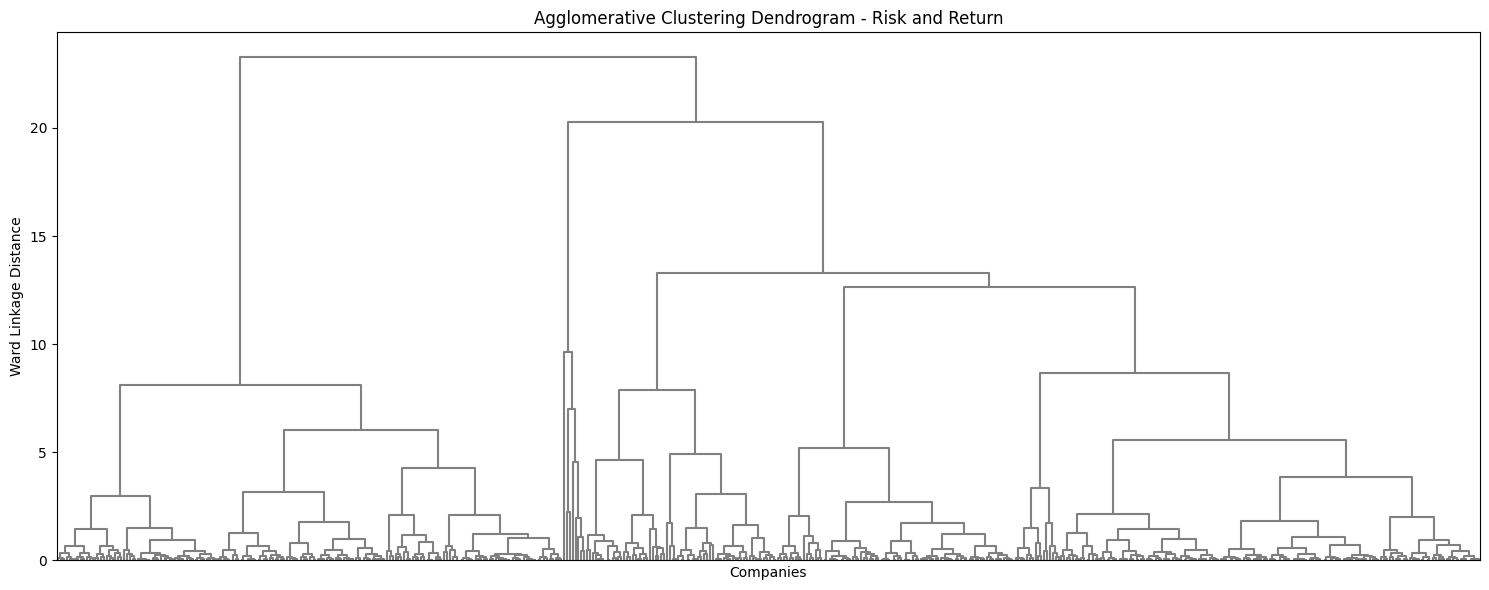

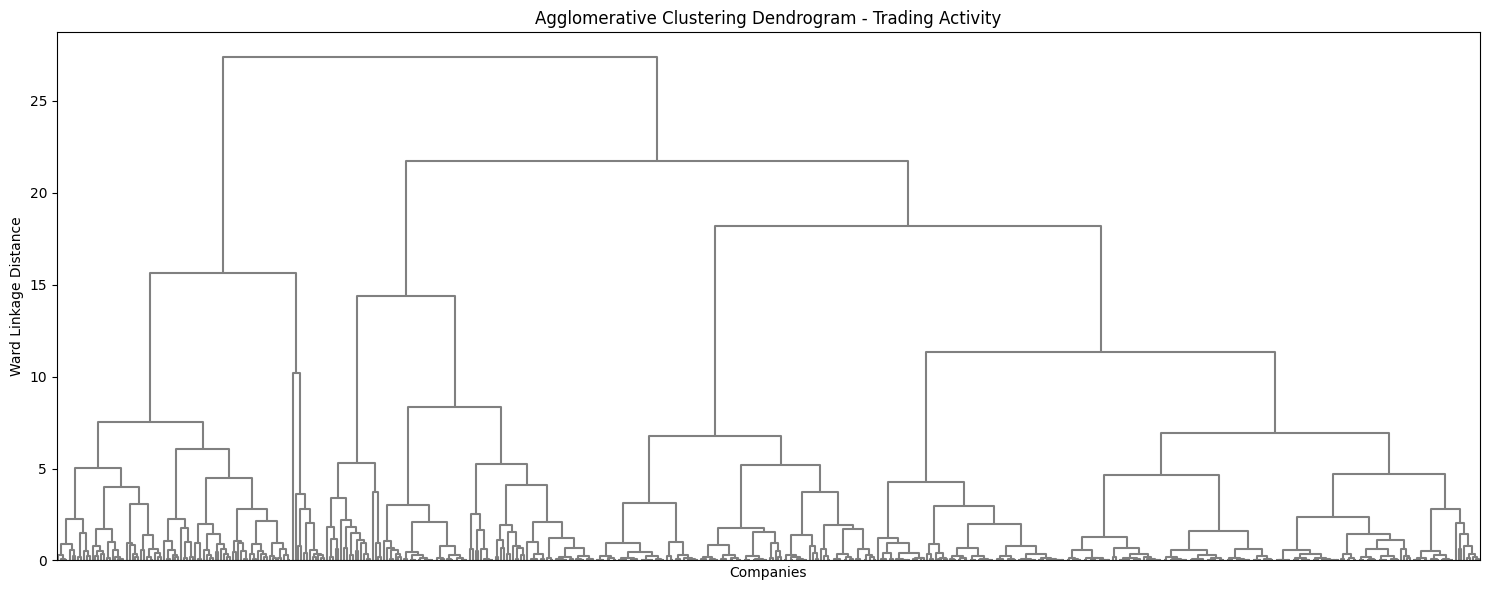


Both dendrograms generated and saved successfully!


In [ ]:

# TASK 2.2 - AGGLOMERATIVE CLUSTERING
# STEP 1: GENERATE DENDROGRAMS

import matplotlib.pyplot as plt
import numpy as np
import os

from scipy.cluster.hierarchy import linkage, dendrogram

# Extract numerical features (exclude ticker)
risk_X = risk_scaled.drop(
    columns=["Ticker"]
).to_numpy()

rfm_X = rfm_scaled.drop(
    columns=["Ticker"]
).to_numpy()

# Check both datasets
assert risk_X.shape == (498, 2)
assert rfm_X.shape == (498, 3)

assert np.isfinite(risk_X).all()
assert np.isfinite(rfm_X).all()

# Confirm company alignment
assert risk_scaled["Ticker"].equals(
    rfm_scaled["Ticker"]
)

print("Both feature matrices verified.")
print("Risk and Return:", risk_X.shape)
print("Trading Activity:", rfm_X.shape)

# --------------------------------
# DENDROGRAM 1: RISK AND RETURN
# --------------------------------

risk_linkage = linkage(
    risk_X,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(15, 6))

dendrogram(
    risk_linkage,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="grey"
)

plt.title(
    "Agglomerative Clustering Dendrogram - Risk and Return"
)

plt.xlabel("Companies")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()

plt.savefig(
    os.path.join(data_folder, "Risk_Return_Dendrogram.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# --------------------------------
# DENDROGRAM 2: TRADING ACTIVITY
# --------------------------------

rfm_linkage = linkage(
    rfm_X,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(15, 6))

dendrogram(
    rfm_linkage,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="grey"
)

plt.title(
    "Agglomerative Clustering Dendrogram - Trading Activity"
)

plt.xlabel("Companies")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()

plt.savefig(
    os.path.join(data_folder, "RFM_Dendrogram.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nBoth dendrograms generated and saved successfully!")


In [ ]:

# TASK 2.2 - STEP 2: SILHOUETTE SCORE COMPARISON

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import pandas as pd
import os

# Two separate datasets
datasets = {
    "Risk and Return": risk_X,
    "Trading Activity": rfm_X
}

silhouette_results = []
cluster_size_results = []

# Test cluster counts from 2 to 8
for dataset_name, X in datasets.items():

    print("\nANALYSING:", dataset_name)

    for k in range(2, 9):

        # Ward linkage with Euclidean distance
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        # Calculate silhouette score
        score = silhouette_score(X, labels)

        # Calculate cluster sizes
        sizes = pd.Series(labels).value_counts().sort_index()

        silhouette_results.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Silhouette_Score": score,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max()
        })

        # Record individual cluster sizes
        for cluster, size in sizes.items():

            cluster_size_results.append({
                "Dataset": dataset_name,
                "Clusters": k,
                "Cluster": cluster,
                "Companies": size
            })

# Create comparison tables
silhouette_df = pd.DataFrame(silhouette_results)

cluster_sizes_df = pd.DataFrame(cluster_size_results)

print("\nSILHOUETTE SCORE COMPARISON")

display(
    silhouette_df.round(4)
)

print("\nINDIVIDUAL CLUSTER SIZES")

display(cluster_sizes_df)

# Save results
silhouette_df.to_csv(
    os.path.join(data_folder, "Agglomerative_Silhouette_Results.csv"),
    index=False
)

cluster_sizes_df.to_csv(
    os.path.join(data_folder, "Agglomerative_Cluster_Sizes.csv"),
    index=False
)

print("\nSILHOUETTE ANALYSIS COMPLETED!")
print("Results saved successfully!")



ANALYSING: Risk and Return

ANALYSING: Trading Activity

SILHOUETTE SCORE COMPARISON


,Dataset,Clusters,Silhouette_Score,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.2888,177,321
1,Risk and Return,3,0.3207,8,313
2,Risk and Return,4,0.2973,8,246
3,Risk and Return,5,0.2885,8,177
4,Risk and Return,6,0.2895,1,177
5,Risk and Return,7,0.2967,1,177
6,Risk and Return,8,0.2792,1,147
7,Trading Activity,2,0.3587,94,404
8,Trading Activity,3,0.3160,94,310
9,Trading Activity,4,0.2876,94,211



INDIVIDUAL CLUSTER SIZES


,Dataset,Clusters,Cluster,Companies
0,Risk and Return,2,0,321
1,Risk and Return,2,1,177
2,Risk and Return,3,0,313
3,Risk and Return,3,1,177
4,Risk and Return,3,2,8
...,...,...,...,...
65,Trading Activity,8,3,99
66,Trading Activity,8,4,11
67,Trading Activity,8,5,20
68,Trading Activity,8,6,66



SILHOUETTE ANALYSIS COMPLETED!
Results saved successfully!


In [ ]:

# TASK 2.2 - STEP 3: CLUSTER PROFILE COMPARISON

from sklearn.cluster import AgglomerativeClustering
import pandas as pd
import os

# Candidate cluster counts based on silhouette results
candidates = {
    "Risk and Return": [2, 3],
    "Trading Activity": [2, 3, 6]
}

profile_results = []

for dataset_name, cluster_counts in candidates.items():

    if dataset_name == "Risk and Return":

        X = risk_X

        original_data = risk_return[
            ["Ticker", "Mean_Weekly_Return", "Weekly_Beta"]
        ].copy()

        profile_columns = [
            "Mean_Weekly_Return",
            "Weekly_Beta"
        ]

    else:

        X = rfm_X

        original_data = trading_activity[
            ["Ticker", "Recency", "Frequency", "Monetary_USD"]
        ].copy()

        profile_columns = [
            "Recency",
            "Frequency",
            "Monetary_USD"
        ]

    for k in cluster_counts:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward",
            metric="euclidean"
        )

        labels = model.fit_predict(X)

        # Attach cluster labels to original company data
        labelled_data = original_data.copy()
        labelled_data["Cluster"] = labels

        # Calculate cluster sizes
        sizes = labelled_data["Cluster"].value_counts().sort_index()

        print("\n===================================")
        print(dataset_name, "- K =", k)
        print("===================================")

        print("\nCLUSTER SIZES")
        display(sizes.to_frame("Number_of_Companies"))

        print("\nCLUSTER PROFILES - MEAN VALUES")

        mean_profile = labelled_data.groupby(
            "Cluster"
        )[profile_columns].mean()

        display(mean_profile.round(4))

        print("\nCLUSTER PROFILES - MEDIAN VALUES")

        median_profile = labelled_data.groupby(
            "Cluster"
        )[profile_columns].median()

        display(median_profile.round(4))

        # Save individual company assignments
        assignment_file = (
            f"{dataset_name.replace(' ', '_')}_K{k}_Assignments.csv"
        )

        labelled_data.to_csv(
            os.path.join(data_folder, assignment_file),
            index=False
        )

        # Store mean profiles for combined report
        for cluster in mean_profile.index:

            record = {
                "Dataset": dataset_name,
                "Clusters": k,
                "Cluster": cluster,
                "Companies": int(sizes.loc[cluster])
            }

            record.update(
                mean_profile.loc[cluster].to_dict()
            )

            profile_results.append(record)

# Save all mean profiles
profiles_df = pd.DataFrame(profile_results)

profiles_df.to_csv(
    os.path.join(data_folder, "Agglomerative_Cluster_Profiles.csv"),
    index=False
)

print("\nALL CANDIDATE CLUSTER PROFILES SAVED!")



Risk and Return - K = 2

CLUSTER SIZES


,Number_of_Companies
Cluster,
0,321
1,177



CLUSTER PROFILES - MEAN VALUES


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.0036,1.2077
1,0.0021,0.5789



CLUSTER PROFILES - MEDIAN VALUES


,Mean_Weekly_Return,Weekly_Beta
Cluster,,
0,0.0031,1.1124
1,0.0020,0.5866


... (21 outputs left out)

,Recency,Frequency,Monetary_USD
Cluster,,,
0,11.1374,2.9479,1.109817e+10
1,14.6216,4.9189,2.532129e+10
2,110.8333,0.1667,1.709857e+11
3,11.8687,2.2626,4.644786e+10
4,47.4390,2.3537,2.730826e+10
5,19.3500,4.5500,3.311300e+11



CLUSTER PROFILES - MEDIAN VALUES


,Recency,Frequency,Monetary_USD
Cluster,,,
0,11.0,3.0,1.078591e+10
1,11.0,5.0,2.111835e+10
2,102.0,0.0,2.502932e+10
3,11.0,2.0,3.606800e+10
4,49.0,2.0,1.988583e+10
5,16.0,5.0,2.100764e+11



ALL CANDIDATE CLUSTER PROFILES SAVED!


In [ ]:

# INVESTIGATE THE 8-COMPANY RISK AND RETURN CLUSTER

risk_k3 = pd.read_csv(
    os.path.join(
        data_folder,
        "Risk_and_Return_K3_Assignments.csv"
    )
)

# Display the eight companies in Cluster 2
small_cluster = risk_k3[
    risk_k3["Cluster"] == 2
].copy()

print("EIGHT COMPANIES IN THE SMALL CLUSTER")
print("------------------------------------")

display(small_cluster)

print("\nCLUSTER 2 SUMMARY")
display(
    small_cluster[
        ["Mean_Weekly_Return", "Weekly_Beta"]
    ].describe().round(4)
)

print("\nNUMBER OF COMPANIES:", len(small_cluster))


EIGHT COMPANIES IN THE SMALL CLUSTER
------------------------------------


,Ticker,Mean_Weekly_Return,Weekly_Beta,Cluster
39,APP,0.014393,2.434869,2
104,COIN,0.006697,3.004326,2
121,CVNA,0.010964,3.778560,2
201,GEV,0.024936,1.338606,2
336,NVDA,0.013624,2.125953,2
382,RDDT,0.038491,2.486226,2
403,SMCI,0.017772,1.783662,2
468,VRT,0.012583,2.001480,2



CLUSTER 2 SUMMARY


,Mean_Weekly_Return,Weekly_Beta
count,8.0000,8.0000
mean,0.0174,2.3692
std,0.0100,0.7566
min,0.0067,1.3386
25%,0.0122,1.9470
50%,0.0140,2.2804
75%,0.0196,2.6158
max,0.0385,3.7786



NUMBER OF COMPANIES: 8


In [ ]:

# TASK 2.2 - FINAL AGGLOMERATIVE CLUSTER ASSIGNMENTS

from sklearn.cluster import AgglomerativeClustering
import pandas as pd
import os

# --------------------------------
# RISK AND RETURN - 3 CLUSTERS
# --------------------------------

risk_final_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward",
    metric="euclidean"
)

risk_final_labels = risk_final_model.fit_predict(risk_X)

risk_final = risk_return.copy()

risk_final["Agglomerative_Cluster"] = risk_final_labels

# --------------------------------
# TRADING ACTIVITY - 2 CLUSTERS
# --------------------------------

rfm_final_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

rfm_final_labels = rfm_final_model.fit_predict(rfm_X)

rfm_final = trading_activity.copy()

rfm_final["Agglomerative_Cluster"] = rfm_final_labels

# --------------------------------
# DISPLAY FINAL RESULTS
# --------------------------------

print("FINAL RISK AND RETURN CLUSTERS")
display(
    risk_final["Agglomerative_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Companies")
)

print("\nFINAL TRADING ACTIVITY CLUSTERS")
display(
    rfm_final["Agglomerative_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Companies")
)

# --------------------------------
# SAVE FINAL ASSIGNMENTS
# --------------------------------

risk_final.to_csv(
    os.path.join(data_folder, "Final_Risk_Return_Clusters.csv"),
    index=False
)

rfm_final.to_csv(
    os.path.join(data_folder, "Final_RFM_Clusters.csv"),
    index=False
)

print("\nFINAL AGGLOMERATIVE CLUSTER ASSIGNMENTS SAVED!")


FINAL RISK AND RETURN CLUSTERS


,Companies
Agglomerative_Cluster,
0,313
1,177
2,8



FINAL TRADING ACTIVITY CLUSTERS


,Companies
Agglomerative_Cluster,
0,404
1,94



FINAL AGGLOMERATIVE CLUSTER ASSIGNMENTS SAVED!



ANALYSING: Risk and Return

ANALYSING: Trading Activity

K-MEANS COMPARISON RESULTS


,Dataset,Clusters,Silhouette_Score,Inertia,Smallest_Cluster,Largest_Cluster
0,Risk and Return,2,0.3998,659.4609,147,351
1,Risk and Return,3,0.3497,498.0967,9,283
2,Risk and Return,4,0.3365,386.9884,8,192
3,Risk and Return,5,0.3311,318.7087,2,167
4,Risk and Return,6,0.3516,265.4161,2,185
5,Risk and Return,7,0.3362,225.3821,2,148
6,Risk and Return,8,0.3284,195.1958,2,128
7,Trading Activity,2,0.4190,1094.0497,72,426
8,Trading Activity,3,0.3245,818.2375,65,276
9,Trading Activity,4,0.3405,625.2121,61,216



INDIVIDUAL CLUSTER SIZES


,Dataset,Clusters,Cluster,Companies
0,Risk and Return,2,0,351
1,Risk and Return,2,1,147
2,Risk and Return,3,0,283
3,Risk and Return,3,1,206
4,Risk and Return,3,2,9
...,...,...,...,...
65,Trading Activity,8,3,150
66,Trading Activity,8,4,11
67,Trading Activity,8,5,21
68,Trading Activity,8,6,1


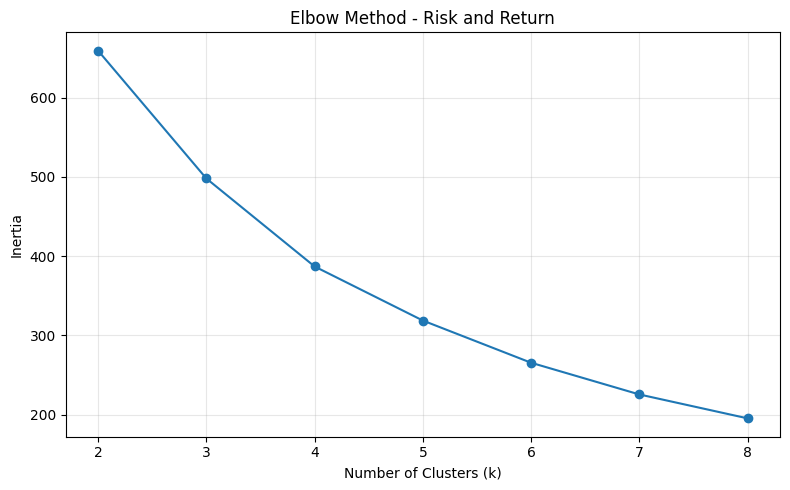

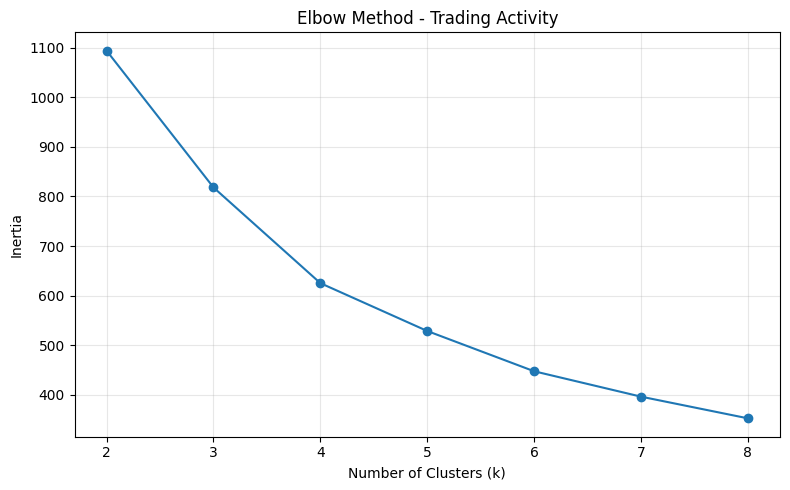


K-MEANS ANALYSIS COMPLETED!
Results and elbow graphs saved successfully!


In [ ]:

# TASK 2.3 - K-MEANS CLUSTERING
# STEP 1: TEST K VALUES FROM 2 TO 8

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Check that both datasets are available and aligned
assert risk_scaled["Ticker"].equals(rfm_scaled["Ticker"])

risk_X = risk_scaled.drop(columns=["Ticker"]).to_numpy()
rfm_X = rfm_scaled.drop(columns=["Ticker"]).to_numpy()

assert risk_X.shape == (498, 2)
assert rfm_X.shape == (498, 3)

datasets = {
    "Risk and Return": risk_X,
    "Trading Activity": rfm_X
}

kmeans_results = []
kmeans_sizes = []

# Store candidate models and labels for later use
kmeans_candidates = {}

for dataset_name, X in datasets.items():

    print("\nANALYSING:", dataset_name)

    for k in range(2, 9):

        # Run K-means with multiple initialisations
        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=50,
            random_state=42
        )

        labels = model.fit_predict(X)

        # Calculate silhouette score
        score = silhouette_score(X, labels)

        # Calculate cluster sizes
        sizes = pd.Series(labels).value_counts().sort_index()

        # Store model and assignments
        kmeans_candidates[(dataset_name, k)] = {
            "model": model,
            "labels": labels
        }

        # Record overall results
        kmeans_results.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Silhouette_Score": score,
            "Inertia": model.inertia_,
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max()
        })

        # Record individual cluster sizes
        for cluster, size in sizes.items():

            kmeans_sizes.append({
                "Dataset": dataset_name,
                "Clusters": k,
                "Cluster": cluster,
                "Companies": size
            })

# Create result tables
kmeans_results_df = pd.DataFrame(kmeans_results)

kmeans_sizes_df = pd.DataFrame(kmeans_sizes)

print("\nK-MEANS COMPARISON RESULTS")

display(kmeans_results_df.round(4))

print("\nINDIVIDUAL CLUSTER SIZES")

display(kmeans_sizes_df)

# ---------------------------------
# ELBOW METHOD VISUALISATIONS
# ---------------------------------

for dataset_name in datasets:

    subset = kmeans_results_df[
        kmeans_results_df["Dataset"] == dataset_name
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        subset["Clusters"],
        subset["Inertia"],
        marker="o"
    )

    plt.title("Elbow Method - " + dataset_name)

    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")

    plt.xticks(range(2, 9))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    filename = (
        dataset_name.replace(" ", "_") +
        "_KMeans_Elbow.png"
    )

    plt.savefig(
        os.path.join(data_folder, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ---------------------------------
# SAVE RESULTS
# ---------------------------------

kmeans_results_df.to_csv(
    os.path.join(data_folder, "KMeans_Comparison_Results.csv"),
    index=False
)

kmeans_sizes_df.to_csv(
    os.path.join(data_folder, "KMeans_Cluster_Sizes.csv"),
    index=False
)

print("\nK-MEANS ANALYSIS COMPLETED!")
print("Results and elbow graphs saved successfully!")


In [ ]:

# TASK 2.3 - FINAL K-MEANS ASSIGNMENTS

import pandas as pd
import os

# Retrieve the selected K=2 models and labels
risk_kmeans_labels = kmeans_candidates[
    ("Risk and Return", 2)
]["labels"]

rfm_kmeans_labels = kmeans_candidates[
    ("Trading Activity", 2)
]["labels"]

# --------------------------------
# RISK AND RETURN ASSIGNMENTS
# --------------------------------

risk_kmeans_final = risk_return.copy()

risk_kmeans_final["KMeans_Cluster"] = risk_kmeans_labels

# --------------------------------
# TRADING ACTIVITY ASSIGNMENTS
# --------------------------------

rfm_kmeans_final = trading_activity.copy()

rfm_kmeans_final["KMeans_Cluster"] = rfm_kmeans_labels

# --------------------------------
# DISPLAY CLUSTER SIZES
# --------------------------------

print("FINAL K-MEANS RISK AND RETURN")

display(
    risk_kmeans_final["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Companies")
)

print("\nFINAL K-MEANS TRADING ACTIVITY")

display(
    rfm_kmeans_final["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Companies")
)

# --------------------------------
# SAVE ASSIGNMENTS
# --------------------------------

risk_kmeans_final.to_csv(
    os.path.join(data_folder, "Final_KMeans_Risk_Return.csv"),
    index=False
)

rfm_kmeans_final.to_csv(
    os.path.join(data_folder, "Final_KMeans_RFM.csv"),
    index=False
)

print("\nFINAL K-MEANS ASSIGNMENTS SAVED SUCCESSFULLY!")


FINAL K-MEANS RISK AND RETURN


,Companies
KMeans_Cluster,
0,351
1,147



FINAL K-MEANS TRADING ACTIVITY


,Companies
KMeans_Cluster,
0,72
1,426



FINAL K-MEANS ASSIGNMENTS SAVED SUCCESSFULLY!


In [ ]:

# TASK 2.4 - CLUSTER PROFILES AND COMPARISON

import pandas as pd
import numpy as np
import os

# -----------------------------------
# 1. RISK AND RETURN PROFILES
# -----------------------------------

risk_ag = risk_return.copy()
risk_ag["Cluster"] = risk_final["Agglomerative_Cluster"].values

risk_km = risk_return.copy()
risk_km["Cluster"] = risk_kmeans_final["KMeans_Cluster"].values

print("AGGLOMERATIVE - RISK AND RETURN")
display(
    risk_ag.groupby("Cluster").agg(
        Companies=("Ticker", "count"),
        Mean_Return=("Mean_Weekly_Return", "mean"),
        Median_Return=("Mean_Weekly_Return", "median"),
        Mean_Beta=("Weekly_Beta", "mean"),
        Median_Beta=("Weekly_Beta", "median")
    ).round(4)
)

print("\nK-MEANS - RISK AND RETURN")
display(
    risk_km.groupby("Cluster").agg(
        Companies=("Ticker", "count"),
        Mean_Return=("Mean_Weekly_Return", "mean"),
        Median_Return=("Mean_Weekly_Return", "median"),
        Mean_Beta=("Weekly_Beta", "mean"),
        Median_Beta=("Weekly_Beta", "median")
    ).round(4)
)

# -----------------------------------
# 2. TRADING ACTIVITY PROFILES
# -----------------------------------

rfm_ag = trading_activity.copy()
rfm_ag["Cluster"] = rfm_final["Agglomerative_Cluster"].values

rfm_km = trading_activity.copy()
rfm_km["Cluster"] = rfm_kmeans_final["KMeans_Cluster"].values

def rfm_profile(df):
    return df.groupby("Cluster").agg(
        Companies=("Ticker", "count"),
        Mean_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Mean_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Mean_Monetary_USD=("Monetary_USD", "mean"),
        Median_Monetary_USD=("Monetary_USD", "median")
    )

print("\nAGGLOMERATIVE - TRADING ACTIVITY")
display(rfm_profile(rfm_ag).round(2))

print("\nK-MEANS - TRADING ACTIVITY")
display(rfm_profile(rfm_km).round(2))

# -----------------------------------
# 3. SAVE PROFILE RESULTS
# -----------------------------------

risk_ag_profile = risk_ag.groupby("Cluster").mean(
    numeric_only=True
)

risk_km_profile = risk_km.groupby("Cluster").mean(
    numeric_only=True
)

rfm_ag_profile = rfm_ag.groupby("Cluster").mean(
    numeric_only=True
)

rfm_km_profile = rfm_km.groupby("Cluster").mean(
    numeric_only=True
)

risk_ag_profile.to_csv(
    os.path.join(data_folder, "Risk_Agglomerative_Profile.csv")
)

risk_km_profile.to_csv(
    os.path.join(data_folder, "Risk_KMeans_Profile.csv")
)

rfm_ag_profile.to_csv(
    os.path.join(data_folder, "RFM_Agglomerative_Profile.csv")
)

rfm_km_profile.to_csv(
    os.path.join(data_folder, "RFM_KMeans_Profile.csv")
)

print("\nALL FOUR CLUSTER PROFILES SAVED SUCCESSFULLY!")


AGGLOMERATIVE - RISK AND RETURN


,Companies,Mean_Return,Median_Return,Mean_Beta,Median_Beta
Cluster,,,,,
0,313,0.0032,0.003,1.1780,1.1004
1,177,0.0021,0.002,0.5789,0.5866
2,8,0.0174,0.014,2.3692,2.2804



K-MEANS - RISK AND RETURN


,Companies,Mean_Return,Median_Return,Mean_Beta,Median_Beta
Cluster,,,,,
0,351,0.0020,0.0020,0.7986,0.8296
1,147,0.0054,0.0048,1.4274,1.3501



AGGLOMERATIVE - TRADING ACTIVITY


,Companies,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary_USD,Median_Monetary_USD
Cluster,,,,,,,
0,404,12.36,11.0,3.22,3.0,3.820898e+10,1.547309e+10
1,94,55.53,53.0,2.07,2.0,4.565006e+10,2.095020e+10



K-MEANS - TRADING ACTIVITY


,Companies,Mean_Recency,Median_Recency,Mean_Frequency,Median_Frequency,Mean_Monetary_USD,Median_Monetary_USD
Cluster,,,,,,,
0,72,62.49,55.0,1.85,2.0,8.060058e+10,2.308445e+10
1,426,13.42,11.0,3.20,3.0,3.268613e+10,1.556962e+10



ALL FOUR CLUSTER PROFILES SAVED SUCCESSFULLY!


In [ ]:

# COMPARE AGGLOMERATIVE AND K-MEANS

from sklearn.metrics import adjusted_rand_score

# Verify company alignment
assert risk_final["Ticker"].equals(
    risk_kmeans_final["Ticker"]
)

assert rfm_final["Ticker"].equals(
    rfm_kmeans_final["Ticker"]
)

# Calculate ARI
risk_ari = adjusted_rand_score(
    risk_final["Agglomerative_Cluster"],
    risk_kmeans_final["KMeans_Cluster"]
)

rfm_ari = adjusted_rand_score(
    rfm_final["Agglomerative_Cluster"],
    rfm_kmeans_final["KMeans_Cluster"]
)

print("ALGORITHM AGREEMENT COMPARISON")

print("Risk and Return ARI:", round(risk_ari, 4))

print("Trading Activity ARI:", round(rfm_ari, 4))

print("\nARI closer to 1 indicates stronger agreement.")
print("ARI around 0 indicates agreement similar to chance.")

comparison = pd.DataFrame({
    "Dataset": ["Risk and Return", "Trading Activity"],
    "Adjusted_Rand_Index": [risk_ari, rfm_ari]
})

display(comparison)

comparison.to_csv(
    os.path.join(data_folder, "Algorithm_ARI_Comparison.csv"),
    index=False
)


ALGORITHM AGREEMENT COMPARISON
Risk and Return ARI: 0.0872
Trading Activity ARI: 0.7537

ARI closer to 1 indicates stronger agreement.
ARI around 0 indicates agreement similar to chance.


,Dataset,Adjusted_Rand_Index
0,Risk and Return,0.087157
1,Trading Activity,0.753690


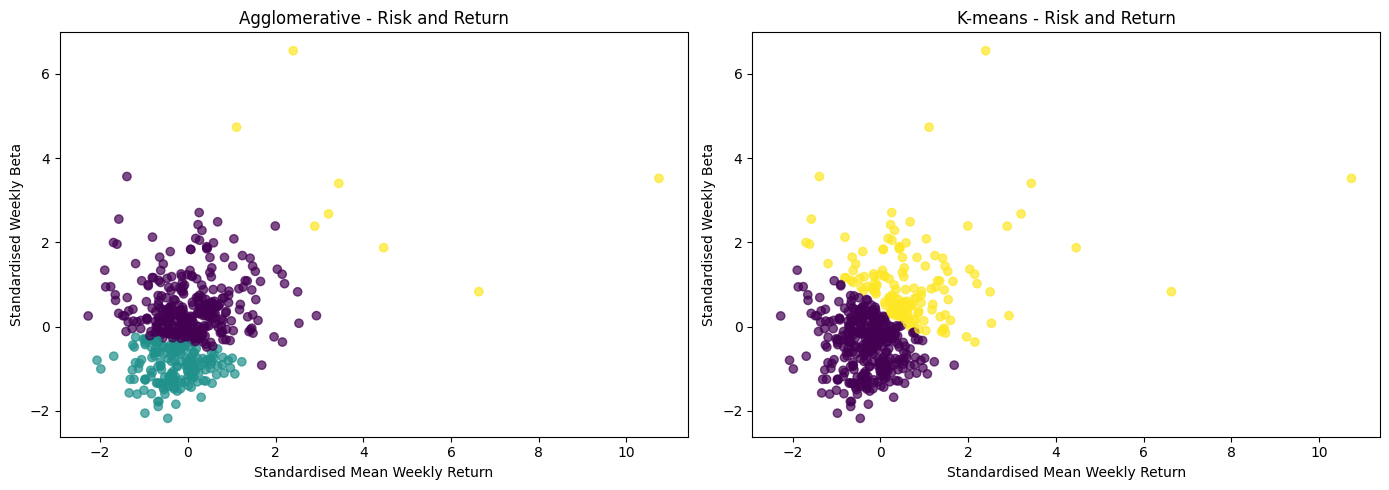

PCA variance explained: [0.4566 0.339 ]
Total variance retained: 0.7956


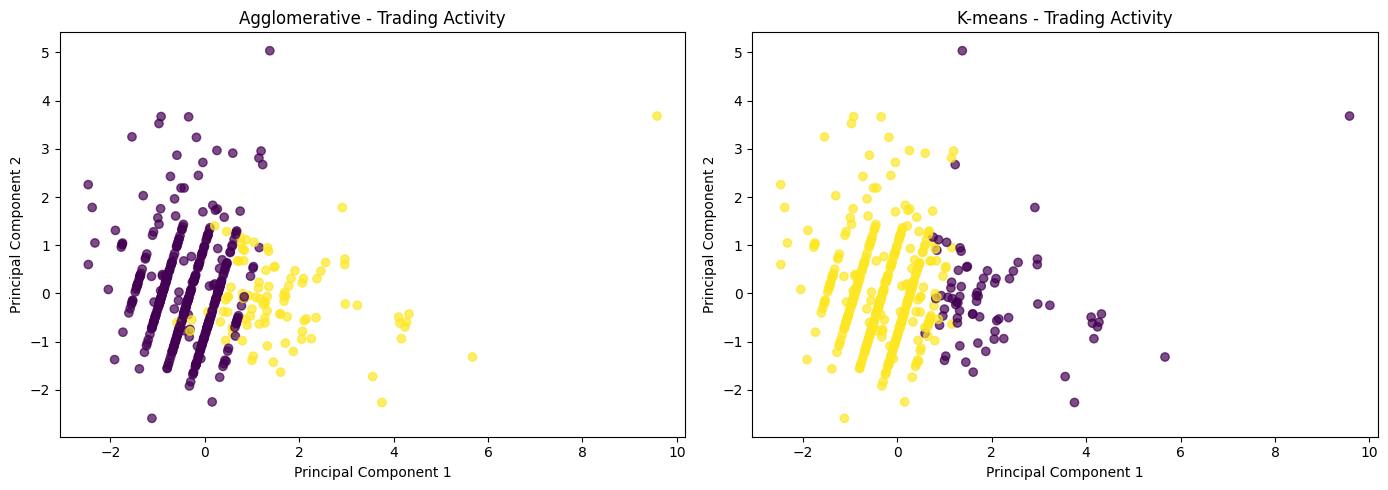


ALL FOUR VISUALISATIONS GENERATED!


In [ ]:

# TASK 2.4 - TWO DIMENSIONAL CLUSTER VISUALISATIONS

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# -----------------------------------
# RISK AND RETURN: DIRECT 2D PLOT
# -----------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    risk_X[:, 0],
    risk_X[:, 1],
    c=risk_final["Agglomerative_Cluster"],
    cmap="viridis",
    alpha=0.7
)

axes[0].set_title("Agglomerative - Risk and Return")
axes[0].set_xlabel("Standardised Mean Weekly Return")
axes[0].set_ylabel("Standardised Weekly Beta")

axes[1].scatter(
    risk_X[:, 0],
    risk_X[:, 1],
    c=risk_kmeans_final["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.7
)

axes[1].set_title("K-means - Risk and Return")
axes[1].set_xlabel("Standardised Mean Weekly Return")
axes[1].set_ylabel("Standardised Weekly Beta")

plt.tight_layout()

plt.savefig(
    os.path.join(data_folder, "Risk_Return_Algorithm_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# -----------------------------------
# TRADING ACTIVITY: PCA REDUCTION
# -----------------------------------

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_X)

print(
    "PCA variance explained:",
    np.round(pca.explained_variance_ratio_, 4)
)

print(
    "Total variance retained:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=rfm_final["Agglomerative_Cluster"],
    cmap="viridis",
    alpha=0.7
)

axes[0].set_title("Agglomerative - Trading Activity")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    rfm_pca[:, 0],
    rfm_pca[:, 1],
    c=rfm_kmeans_final["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.7
)

axes[1].set_title("K-means - Trading Activity")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()

plt.savefig(
    os.path.join(data_folder, "RFM_Algorithm_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nALL FOUR VISUALISATIONS GENERATED!")


RFM CORRELATION MATRIX


,Recency,Frequency,Log_Monetary
Recency,1.0000,-0.3402,0.1647
Frequency,-0.3402,1.0000,0.0219
Log_Monetary,0.1647,0.0219,1.0000


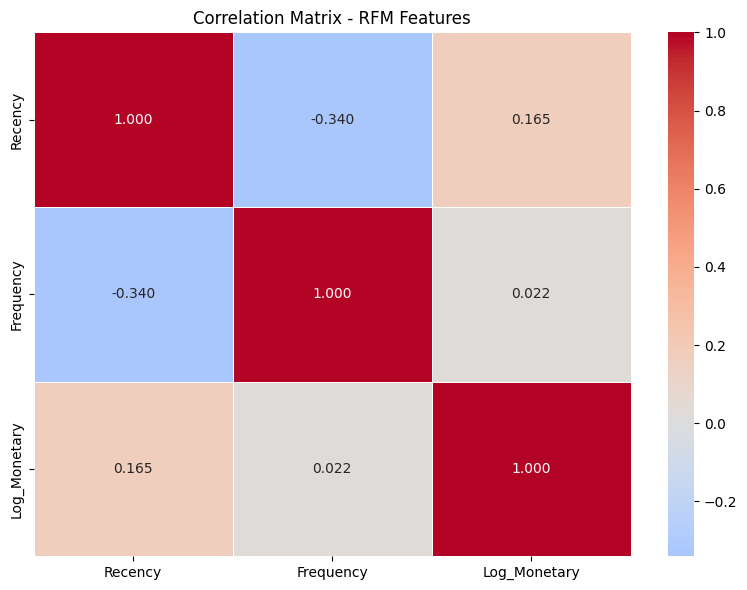


CORRELATION ANALYSIS COMPLETED!


In [ ]:

# TASK 2.5.1 - CORRELATION ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Prepare RFM correlation dataset
correlation_data = trading_activity[
    ["Recency", "Frequency", "Monetary_USD"]
].copy()

# Apply log1p transformation to Monetary
correlation_data["Log_Monetary"] = np.log1p(
    correlation_data["Monetary_USD"]
)

# Select the required three variables
correlation_features = correlation_data[
    ["Recency", "Frequency", "Log_Monetary"]
]

# Calculate Pearson correlation
correlation_matrix = correlation_features.corr(
    method="pearson"
)

print("RFM CORRELATION MATRIX")
display(correlation_matrix.round(4))

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".3f",
    linewidths=0.5
)

plt.title("Correlation Matrix - RFM Features")

plt.tight_layout()

plt.savefig(
    os.path.join(data_folder, "RFM_Correlation_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save correlation results
correlation_matrix.to_csv(
    os.path.join(data_folder, "RFM_Correlation_Matrix.csv")
)

print("\nCORRELATION ANALYSIS COMPLETED!")


In [ ]:

# TASK 2.5.2 - REMOVE MONETARY AND REPEAT CLUSTERING

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
import pandas as pd
import os

# --------------------------------
# 1. PREPARE REDUCED DATASET
# --------------------------------

rf_only = trading_activity[
    ["Ticker", "Recency", "Frequency", "Monetary_USD"]
].copy()

# Keep the same 498 companies
assert len(rf_only) == 498

assert rf_only["Ticker"].equals(
    rfm_final["Ticker"]
)

# Use only Recency and Frequency
rf_features = rf_only[
    ["Recency", "Frequency"]
]

# Standardise the reduced features afresh
rf_scaler = StandardScaler()

rf_scaled = rf_scaler.fit_transform(
    rf_features
)

print("REDUCED FEATURE MATRIX")
print("Companies:", rf_scaled.shape[0])
print("Features:", rf_scaled.shape[1])
print("Features used: Recency and Frequency")

# --------------------------------
# 2. REPEAT WARD CLUSTERING
# --------------------------------

rf_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward",
    metric="euclidean"
)

rf_labels = rf_model.fit_predict(rf_scaled)

rf_only["RF_Cluster"] = rf_labels

print("\nREDUCED RFM CLUSTER SIZES")

display(
    rf_only["RF_Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Companies")
)

# --------------------------------
# 3. COMPARE MEMBERSHIPS USING ARI
# --------------------------------

full_rfm_labels = rfm_final[
    "Agglomerative_Cluster"
].values

reduced_ari = adjusted_rand_score(
    full_rfm_labels,
    rf_labels
)

print("\nFULL RFM VS REDUCED R-F COMPARISON")

print("Adjusted Rand Index:", round(reduced_ari, 4))

# --------------------------------
# 4. COMPARE TRADED VALUE PROFILES
# --------------------------------

print("\nFULL RFM CLUSTER MONETARY PROFILES")

full_profile = rfm_final.groupby(
    "Agglomerative_Cluster"
).agg(
    Companies=("Ticker", "count"),
    Mean_Monetary_USD=("Monetary_USD", "mean"),
    Median_Monetary_USD=("Monetary_USD", "median")
)

display(full_profile.round(2))

print("\nREDUCED R-F CLUSTER MONETARY PROFILES")

reduced_profile = rf_only.groupby(
    "RF_Cluster"
).agg(
    Companies=("Ticker", "count"),
    Mean_Monetary_USD=("Monetary_USD", "mean"),
    Median_Monetary_USD=("Monetary_USD", "median")
)

display(reduced_profile.round(2))

# --------------------------------
# 5. SAVE RESULTS
# --------------------------------

rf_only.to_csv(
    os.path.join(data_folder, "Reduced_RF_Cluster_Assignments.csv"),
    index=False
)

reduced_profile.to_csv(
    os.path.join(data_folder, "Reduced_RF_Monetary_Profiles.csv")
)

print("\nMONETARY REMOVAL ANALYSIS COMPLETED!")
print("Reduced clustering results saved successfully!")


REDUCED FEATURE MATRIX
Companies: 498
Features: 2
Features used: Recency and Frequency

REDUCED RFM CLUSTER SIZES


,Companies
RF_Cluster,
0,405
1,93



FULL RFM VS REDUCED R-F COMPARISON
Adjusted Rand Index: 0.9531

FULL RFM CLUSTER MONETARY PROFILES


,Companies,Mean_Monetary_USD,Median_Monetary_USD
Agglomerative_Cluster,,,
0,404,3.820898e+10,1.547309e+10
1,94,4.565006e+10,2.095020e+10



REDUCED R-F CLUSTER MONETARY PROFILES


,Companies,Mean_Monetary_USD,Median_Monetary_USD
RF_Cluster,,,
0,405,3.768854e+10,1.545679e+10
1,93,4.799647e+10,2.105259e+10



MONETARY REMOVAL ANALYSIS COMPLETED!
Reduced clustering results saved successfully!


In [ ]:

# TASK 3.2.1 - STEP 1
# LOCATE THE ORIGINAL COMPANY SECTOR INFORMATION

import os
import pandas as pd

print("SEARCHING FOR COMPANY SECTOR INFORMATION...\n")

# Search the coursework folder and its data folder
search_folders = [main_folder, data_folder]

sector_candidates = []

for folder in search_folders:

    if os.path.exists(folder):

        for filename in os.listdir(folder):

            if filename.lower().endswith(".csv"):

                file_path = os.path.join(folder, filename)

                try:
                    temp = pd.read_csv(file_path, nrows=5)

                    columns = [
                        str(c).strip().lower()
                        for c in temp.columns
                    ]

                    if (
                        "gics sector" in columns
                        and "symbol" in columns
                    ):

                        sector_candidates.append(file_path)

                except Exception:
                    pass

print("SECTOR FILES FOUND:")

for path in sector_candidates:
    print(path)

if len(sector_candidates) == 0:

    print("\nNo sector file found in the two folders.")
    print("We will locate the original ticker list separately.")

else:

    print("\nSector information is available.")


SEARCHING FOR COMPANY SECTOR INFORMATION...

SECTOR FILES FOUND:
/content/drive/MyDrive/6BUIS017W_CWK1/SP500_Daily_Data/SP500_Ticker_List.csv

Sector information is available.


In [ ]:

# TASK 3.2.1 - STEP 2
# LOAD COMPANY SECTOR INFORMATION

sector_df = pd.read_csv(sector_candidates[0])

print("SECTOR DATA LOADED SUCCESSFULLY!")
print("\nDataset dimensions:", sector_df.shape)

print("\nAVAILABLE COLUMNS:")
print(sector_df.columns.tolist())

print("\nFIRST 10 COMPANIES:")
display(sector_df.head(10))


SECTOR DATA LOADED SUCCESSFULLY!

Dataset dimensions: (503, 4)

AVAILABLE COLUMNS:
['Symbol', 'Security', 'GICS Sector', 'Yahoo_Ticker']

FIRST 10 COMPANIES:


,Symbol,Security,GICS Sector,Yahoo_Ticker
0,MMM,3M,Industrials,MMM
1,AOS,A. O. Smith,Industrials,AOS
2,ABT,Abbott Laboratories,Health Care,ABT
3,ABBV,AbbVie,Health Care,ABBV
4,ACN,Accenture,Information Technology,ACN
5,ADBE,Adobe Inc.,Information Technology,ADBE
6,AMD,Advanced Micro Devices,Information Technology,AMD
7,AES,AES Corporation,Utilities,AES
8,AFL,Aflac,Financials,AFL
9,A,Agilent Technologies,Health Care,A


In [ ]:

# TASK 3.2.1 - STEP 3
# CONNECT SECTOR INFORMATION WITH ALL FOUR CLUSTER SOLUTIONS

import pandas as pd
import os

# Prepare sector information
sector_lookup = sector_df[
    ["Symbol", "Security", "GICS Sector"]
].copy()

sector_lookup = sector_lookup.rename(
    columns={"Symbol": "Ticker"}
)

# Remove any duplicate ticker entries if present
sector_lookup = sector_lookup.drop_duplicates(
    subset="Ticker"
)

# Prepare the four clustering datasets
cluster_datasets = {
    "Risk_Agglomerative": (
        risk_final,
        "Agglomerative_Cluster"
    ),
    "Risk_KMeans": (
        risk_kmeans_final,
        "KMeans_Cluster"
    ),
    "RFM_Agglomerative": (
        rfm_final,
        "Agglomerative_Cluster"
    ),
    "RFM_KMeans": (
        rfm_kmeans_final,
        "KMeans_Cluster"
    )
}

sector_cluster_results = {}

for name, (cluster_df, cluster_column) in cluster_datasets.items():

    # Keep ticker and cluster assignment
    temp = cluster_df[
        ["Ticker", cluster_column]
    ].copy()

    # Rename cluster column consistently
    temp = temp.rename(
        columns={cluster_column: "Cluster"}
    )

    # Attach company and sector information
    merged = temp.merge(
        sector_lookup,
        on="Ticker",
        how="left",
        validate="one_to_one"
    )

    # Verify successful matching
    unmatched = merged["GICS Sector"].isna().sum()

    assert len(merged) == 498, (
        f"Unexpected company count in {name}"
    )

    assert unmatched == 0, (
        f"{unmatched} companies have missing sector information"
    )

    sector_cluster_results[name] = merged

    print("\n", name)
    print("Companies matched:", len(merged))
    print("Unmatched companies:", unmatched)

print("\nALL FOUR DATASETS MATCHED SUCCESSFULLY!")

# Save combined company-level datasets
for name, df in sector_cluster_results.items():

    df.to_csv(
        os.path.join(
            data_folder,
            f"{name}_Sector_Assignments.csv"
        ),
        index=False
    )


AssertionError: 2 companies have missing sector information

In [ ]:

# INVESTIGATE THE TWO UNMATCHED COMPANIES

for name, (cluster_df, cluster_column) in cluster_datasets.items():

    check = cluster_df[["Ticker"]].merge(
        sector_lookup[["Ticker", "GICS Sector"]],
        on="Ticker",
        how="left"
    )

    unmatched = check[check["GICS Sector"].isna()]

    print("\nDATASET:", name)
    print("Unmatched companies:", len(unmatched))

    if len(unmatched) > 0:
        display(unmatched)



DATASET: Risk_Agglomerative
Unmatched companies: 2


,Ticker,GICS Sector
58,BF-B,NaN
67,BRK-B,NaN



DATASET: Risk_KMeans
Unmatched companies: 2


,Ticker,GICS Sector
58,BF-B,NaN
67,BRK-B,NaN



DATASET: RFM_Agglomerative
Unmatched companies: 2


,Ticker,GICS Sector
58,BF-B,NaN
67,BRK-B,NaN



DATASET: RFM_KMeans
Unmatched companies: 2


,Ticker,GICS Sector
58,BF-B,NaN
67,BRK-B,NaN


In [ ]:

# FIX TICKER MATCHING USING YAHOO TICKER SYMBOLS

sector_lookup = sector_df[
    ["Yahoo_Ticker", "Security", "GICS Sector"]
].copy()

sector_lookup = sector_lookup.rename(
    columns={"Yahoo_Ticker": "Ticker"}
)

sector_lookup = sector_lookup.drop_duplicates(
    subset="Ticker"
)

print("CORRECTED SECTOR LOOKUP")

display(
    sector_lookup[
        sector_lookup["Ticker"].isin(["BF-B", "BRK-B"])
    ]
)

print("\nSector lookup prepared successfully!")


CORRECTED SECTOR LOOKUP


,Ticker,Security,GICS Sector
60,BRK-B,Berkshire Hathaway,Financials
76,BF-B,Brown–Forman,Consumer Staples



Sector lookup prepared successfully!


In [ ]:

# TASK 3.2.1 - CORRECTED SECTOR MATCHING

sector_cluster_results = {}

for name, (cluster_df, cluster_column) in cluster_datasets.items():

    temp = cluster_df[
        ["Ticker", cluster_column]
    ].copy()

    temp = temp.rename(
        columns={cluster_column: "Cluster"}
    )

    merged = temp.merge(
        sector_lookup,
        on="Ticker",
        how="left",
        validate="one_to_one"
    )

    unmatched = merged["GICS Sector"].isna().sum()

    print("\n", name)
    print("Companies:", len(merged))
    print("Unmatched companies:", unmatched)

    if unmatched > 0:
        display(
            merged[merged["GICS Sector"].isna()]
        )

    assert len(merged) == 498
    assert unmatched == 0

    sector_cluster_results[name] = merged

    merged.to_csv(
        os.path.join(
            data_folder,
            f"{name}_Sector_Assignments.csv"
        ),
        index=False
    )

print("\nALL FOUR DATASETS MATCHED SUCCESSFULLY!")



 Risk_Agglomerative
Companies: 498
Unmatched companies: 0

 Risk_KMeans
Companies: 498
Unmatched companies: 0

 RFM_Agglomerative
Companies: 498
Unmatched companies: 0

 RFM_KMeans
Companies: 498
Unmatched companies: 0

ALL FOUR DATASETS MATCHED SUCCESSFULLY!


In [ ]:

# TASK 3.2.1 - SECTOR COMPOSITION

sector_count_tables = {}
sector_percentage_tables = {}

for name, df in sector_cluster_results.items():

    # Count companies in each sector and cluster
    counts = pd.crosstab(
        df["Cluster"],
        df["GICS Sector"]
    )

    # Calculate percentages within each cluster
    percentages = (
        counts.div(counts.sum(axis=1), axis=0) * 100
    )

    sector_count_tables[name] = counts
    sector_percentage_tables[name] = percentages

    print("\n================================")
    print(name)
    print("SECTOR COMPANY COUNTS")
    print("================================")

    display(counts)

    print("\nSECTOR COMPOSITION (%)")
    display(percentages.round(2))

    counts.to_csv(
        os.path.join(
            data_folder,
            f"{name}_Sector_Counts.csv"
        )
    )

    percentages.to_csv(
        os.path.join(
            data_folder,
            f"{name}_Sector_Percentages.csv"
        )
    )

print("\nALL SECTOR COMPOSITION TABLES SAVED!")



Risk_Agglomerative
SECTOR COMPANY COUNTS


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
0,11,39,4,11,52,29,61,68,15,19,4
1,9,7,28,10,23,31,18,4,9,11,27
2,2,1,0,0,1,0,2,2,0,0,0



SECTOR COMPOSITION (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
0,3.51,12.46,1.28,3.51,16.61,9.27,19.49,21.73,4.79,6.07,1.28
1,5.08,3.95,15.82,5.65,12.99,17.51,10.17,2.26,5.08,6.21,15.25
2,25.00,12.50,0.00,0.00,12.50,0.00,25.00,25.00,0.00,0.00,0.00



Risk_KMeans
SECTOR COMPANY COUNTS


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
0,15,26,31,16,56,58,53,22,19,27,28
1,7,21,1,5,20,2,28,52,5,3,3


... (7 outputs left out)

GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
0,2,8,5,1,12,8,5,15,6,0,10
1,20,39,27,20,64,52,76,59,18,30,21



SECTOR COMPOSITION (%)


GICS Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
Cluster,,,,,,,,,,,
0,2.78,11.11,6.94,1.39,16.67,11.11,6.94,20.83,8.33,0.00,13.89
1,4.69,9.15,6.34,4.69,15.02,12.21,17.84,13.85,4.23,7.04,4.93



ALL SECTOR COMPOSITION TABLES SAVED!


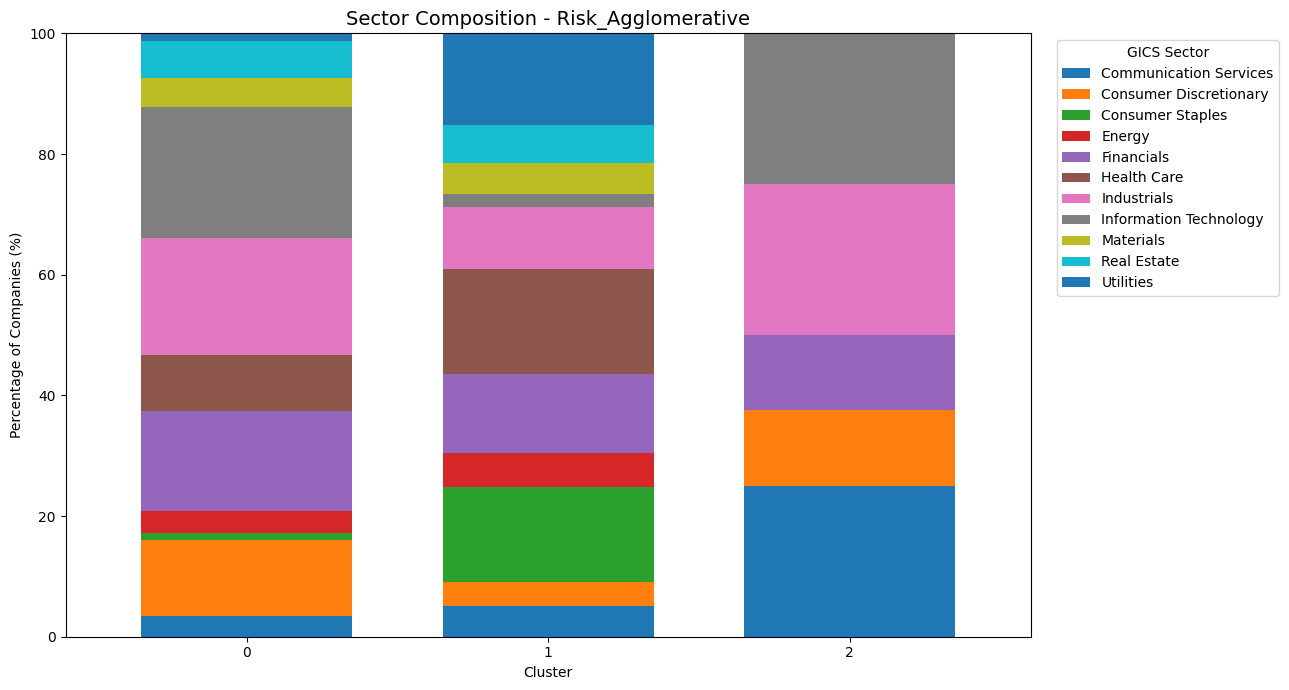

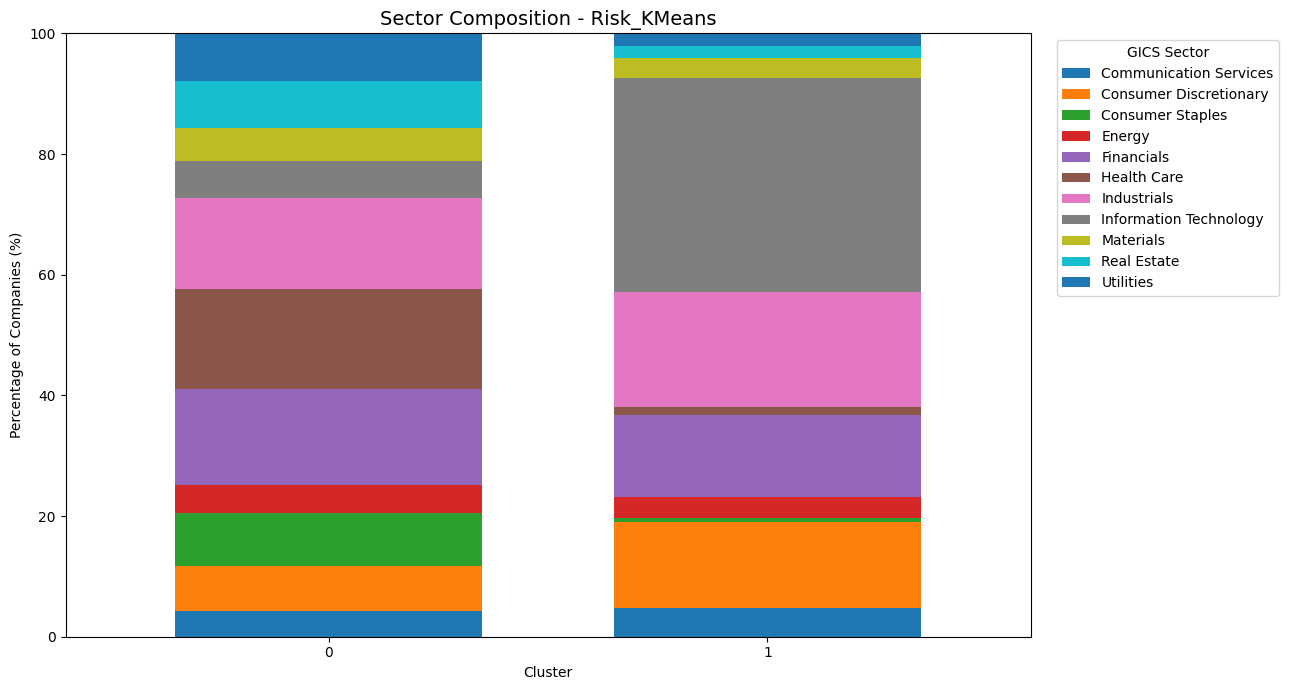

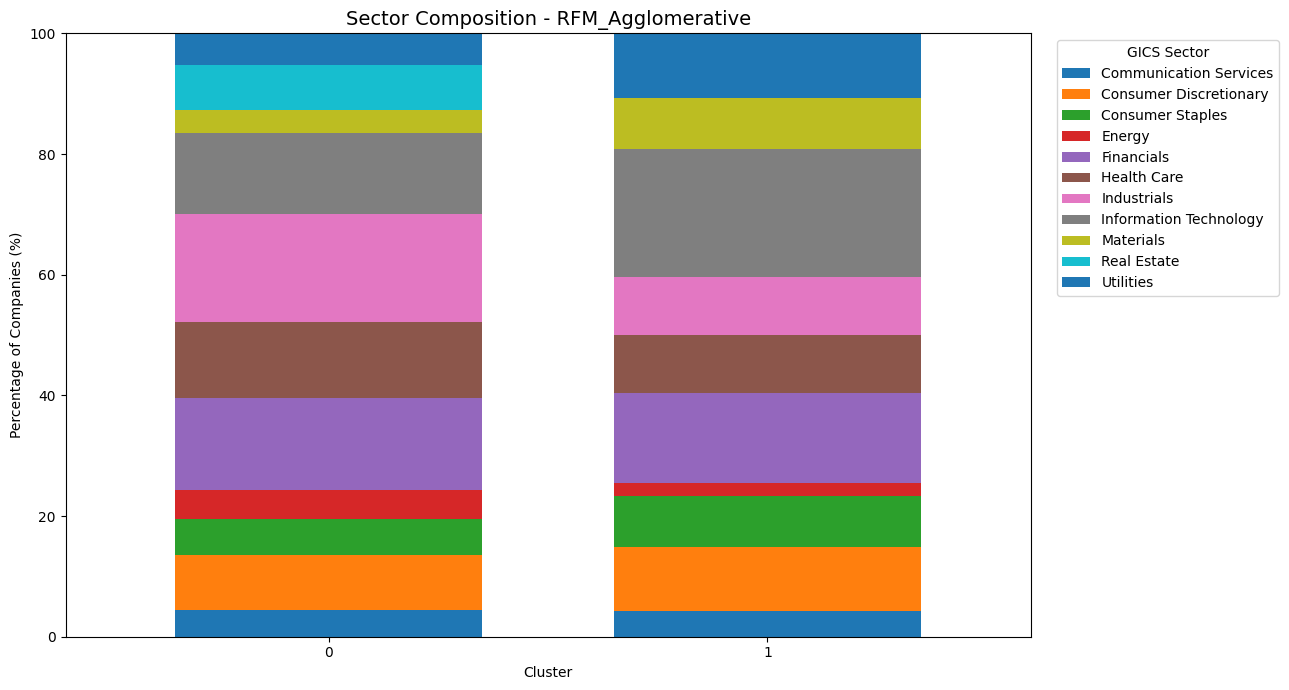

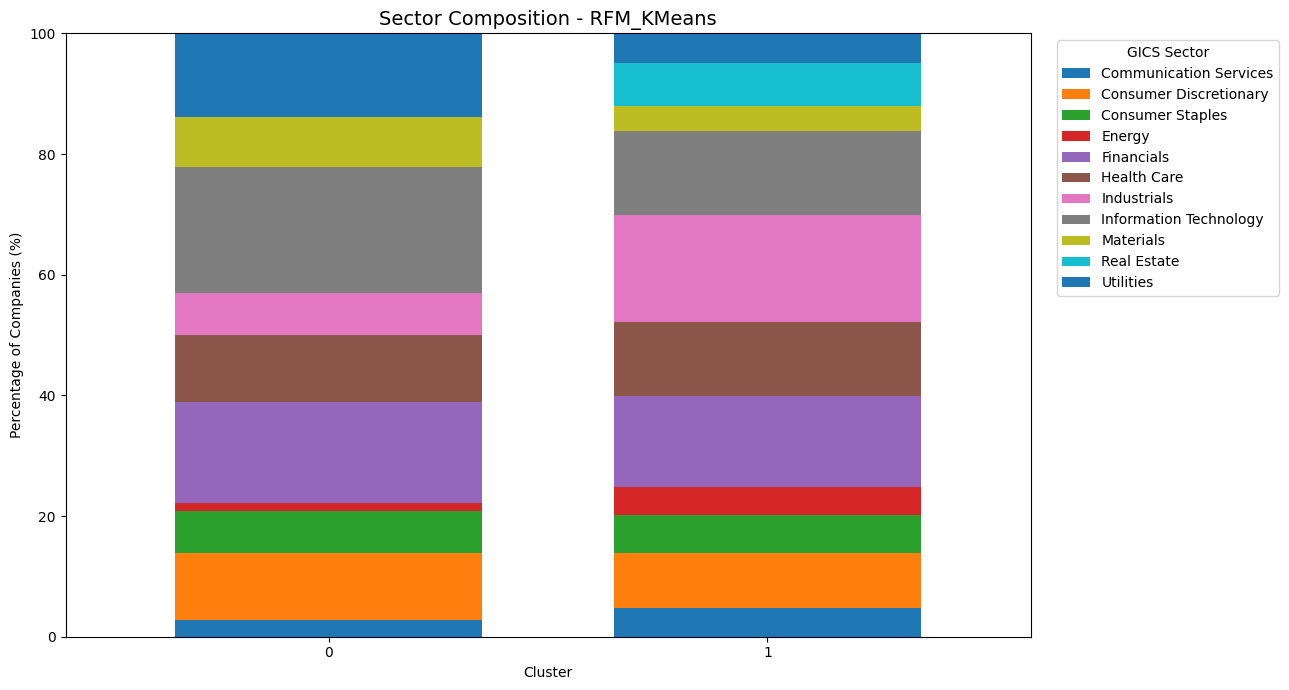


ALL FOUR SECTOR VISUALISATIONS GENERATED!


In [ ]:

# TASK 3.2.1 - STEP 5
# GENERATE FOUR SECTOR COMPOSITION CHARTS

import matplotlib.pyplot as plt
import os

for name, percentages in sector_percentage_tables.items():

    ax = percentages.plot(
        kind="bar",
        stacked=True,
        figsize=(13, 7),
        width=0.7
    )

    plt.title(
        "Sector Composition - " + name,
        fontsize=14
    )

    plt.xlabel("Cluster")
    plt.ylabel("Percentage of Companies (%)")

    plt.ylim(0, 100)

    plt.xticks(rotation=0)

    plt.legend(
        title="GICS Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            data_folder,
            f"{name}_Sector_Composition.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("\nALL FOUR SECTOR VISUALISATIONS GENERATED!")
